In [1]:
pip install pandas numpy matplotlib scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Isfar\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [2]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from matplotlib.pyplot import figure
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.dates as mdates
from sklearn import linear_model
from sklearn.model_selection import TimeSeriesSplit
from sklearn.svm import SVR
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


Data for this study is collected from **November 18th 2011** to **January 1st 2019** from various sources. The data has **1718** rows in total and **80** columns in total. Data for attributes, such as Oil Price, Standard and Poor’s (S&P) 500 index, Dow Jones Index US Bond rates (10 years), Euro USD exchange rates, prices of precious metals Silver and Platinum and other metals such as Palladium and Rhodium, prices of  US Dollar Index, Eldorado Gold Corporation and Gold Miners ETF were gathered. 

**Attributes:**

**Features**

- Gold ETF :- Date, Open, High, Low, Close and Volume.
- S&P 500 Index :- 'SP_open', 'SP_high', 'SP_low', 'SP_close', 'SP_Ajclose', 'SP_volume' 
- Dow Jones Index :- 'DJ_open','DJ_high', 'DJ_low', 'DJ_close', 'DJ_Ajclose', 'DJ_volume' 
- Eldorado Gold Corporation (EGO) :- 'EG_open', 'EG_high', 'EG_low', 'EG_close', 'EG_Ajclose', 'EG_volume'
- EURO - USD Exchange Rate :- 'EU_Price','EU_open', 'EU_high', 'EU_low', 'EU_Trend' 
- Brent Crude Oil Futures :- 'OF_Price', 'OF_Open', 'OF_High', 'OF_Low', 'OF_Volume', 'OF_Trend'
- Crude Oil WTI USD :- 'OS_Price', 'OS_Open', 'OS_High', 'OS_Low', 'OS_Trend'
- Silver Futures :- 'SF_Price', 'SF_Open', 'SF_High', 'SF_Low', 'SF_Volume', 'SF_Trend'
- US Bond Rate (10 years) :- 'USB_Price', 'USB_Open', 'USB_High','USB_Low', 'USB_Trend' 
- Platinum Price :- 'PLT_Price', 'PLT_Open', 'PLT_High', 'PLT_Low','PLT_Trend'
- Palladium Price :- 'PLD_Price', 'PLD_Open', 'PLD_High', 'PLD_Low','PLD_Trend' 
- Rhodium Prices :- 'RHO_PRICE' 
- US Dollar Index : 'USDI_Price', 'USDI_Open', 'USDI_High','USDI_Low', 'USDI_Volume', 'USDI_Trend' 
- Gold Miners ETF :- 'GDX_Open', 'GDX_High', 'GDX_Low', 'GDX_Close', 'GDX_Adj Close', 'GDX_Volume' 
- Oil ETF USO :- 'USO_Open','USO_High', 'USO_Low', 'USO_Close', 'USO_Adj Close', 'USO_Volume'

**Target Variable**
- Gold ETF :- Adjusted Close

In [3]:
df_final = pd.read_csv(r'C:\Users\Isfar\OneDrive\Desktop\safi MJ\kaggle\input\FINAL_USO_2026.csv',na_values=['null'],index_col='Date',parse_dates=True,infer_datetime_format=True)

C:\Users\Isfar\AppData\Local\Temp\ipykernel_13848\1129992632.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df_final = pd.read_csv(r'C:\Users\Isfar\OneDrive\Desktop\safi MJ\kaggle\input\FINAL_USO_2026.csv',na_values=['null'],index_col='Date',parse_dates=True,infer_datetime_format=True)


In [4]:
df_final.head()

,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,SP_close,...,GDX_Low,GDX_Close,GDX_Adj Close,GDX_Volume,USO_Open,USO_High,USO_Low,USO_Close,USO_Adj Close,USO_Volume
Date,,,,,,,,,,,,,,,,,,,,,
2011-12-15,154.740005,154.949997,151.710007,152.330002,152.330002,21521900,123.029999,123.199997,121.989998,122.180000,...,51.570000,51.680000,48.973877,20605600,36.900002,36.939999,36.049999,36.130001,36.130001,12616700
2011-12-16,154.309998,155.369995,153.899994,155.229996,155.229996,18124300,122.230003,122.949997,121.300003,121.589996,...,52.040001,52.680000,49.921513,16285400,36.180000,36.500000,35.730000,36.270000,36.270000,12578800
2011-12-19,155.479996,155.860001,154.360001,154.869995,154.869995,12547200,122.059998,122.320000,120.029999,120.290001,...,51.029999,51.169998,48.490578,15120200,36.389999,36.450001,35.930000,36.200001,36.200001,7418200
2011-12-20,156.820007,157.429993,156.580002,156.979996,156.979996,9136300,122.180000,124.139999,120.370003,123.930000,...,52.369999,52.990002,50.215282,11644900,37.299999,37.610001,37.220001,37.560001,37.560001,10041600
2011-12-21,156.979996,157.529999,156.130005,157.160004,157.160004,11996100,123.930000,124.360001,122.750000,124.169998,...,52.419998,52.959999,50.186852,8724300,37.669998,38.240002,37.520000,38.110001,38.110001,10728000


In [5]:
df_final.shape

(3632, 80)

So, we have 1718 records in the dataset and 80 columns including Adjusted Close which is our target variable.

In [6]:
df_final.describe()

,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,SP_close,...,GDX_Low,GDX_Close,GDX_Adj Close,GDX_Volume,USO_Open,USO_High,USO_Low,USO_Close,USO_Adj Close,USO_Volume
count,3632.000000,3632.000000,3632.000000,3632.000000,3632.000000,3.632000e+03,3632.000000,3632.000000,3632.000000,3632.000000,...,3632.000000,3632.000000,3632.000000,3.632000e+03,3632.000000,3632.000000,3632.000000,3632.000000,3632.000000,3.632000e+03
mean,171.718012,172.515270,170.834747,171.710509,171.710509,8.915285e+06,2504.674547,2518.461543,2490.040027,2505.283849,...,33.029118,33.486586,32.402729,3.570159e+07,47.927156,48.447577,47.348949,47.918365,47.918365,1.236263e+07
std,75.544754,76.092122,74.790941,75.511856,75.511856,5.502310e+06,2380.949603,2393.294524,2367.908597,2381.552889,...,16.614208,16.925116,16.904254,2.514904e+07,30.910658,31.294571,30.486277,30.916923,30.916923,1.438158e+07
min,100.919998,100.989998,100.230003,100.500000,100.500000,1.436500e+06,122.059998,122.320000,120.029999,120.290001,...,12.400000,12.470000,12.269618,4.729000e+06,7.820000,8.030000,7.670000,7.960000,7.960000,4.317380e+05
25%,121.967501,122.320000,121.495001,121.857500,121.857500,5.617275e+06,207.110001,208.164997,205.852501,207.107502,...,22.580000,22.787501,22.383714,1.874330e+07,18.217500,18.507500,17.860001,18.232500,18.232500,3.607100e+06
50%,155.434998,156.294998,154.580002,155.514999,155.514999,7.638350e+06,2826.935059,2845.529907,2805.295044,2828.429932,...,28.350000,28.740000,27.422670,2.838440e+07,38.220001,38.439999,37.935000,38.180000,38.180000,5.902600e+06
75%,178.954998,179.432495,178.115002,178.714996,178.714996,1.062672e+07,4380.972412,4410.484985,4357.157471,4380.667358,...,37.145000,37.507500,36.034560,4.443895e+07,72.962500,73.629997,72.102499,73.059998,73.059998,1.682500e+07
max,509.510010,509.700012,483.279999,495.899994,495.899994,9.380420e+07,7771.620117,7816.700195,7763.180176,7798.990234,...,114.320000,115.839996,115.839996,2.321536e+08,152.880005,154.080002,150.220001,152.960007,152.960007,1.437719e+08


# Checking Missing Values

In [7]:
df_final.isnull().values.any()

np.False_

That's great ! we dont have any missing values in our dataset

## Effect of Index prices on gold rates

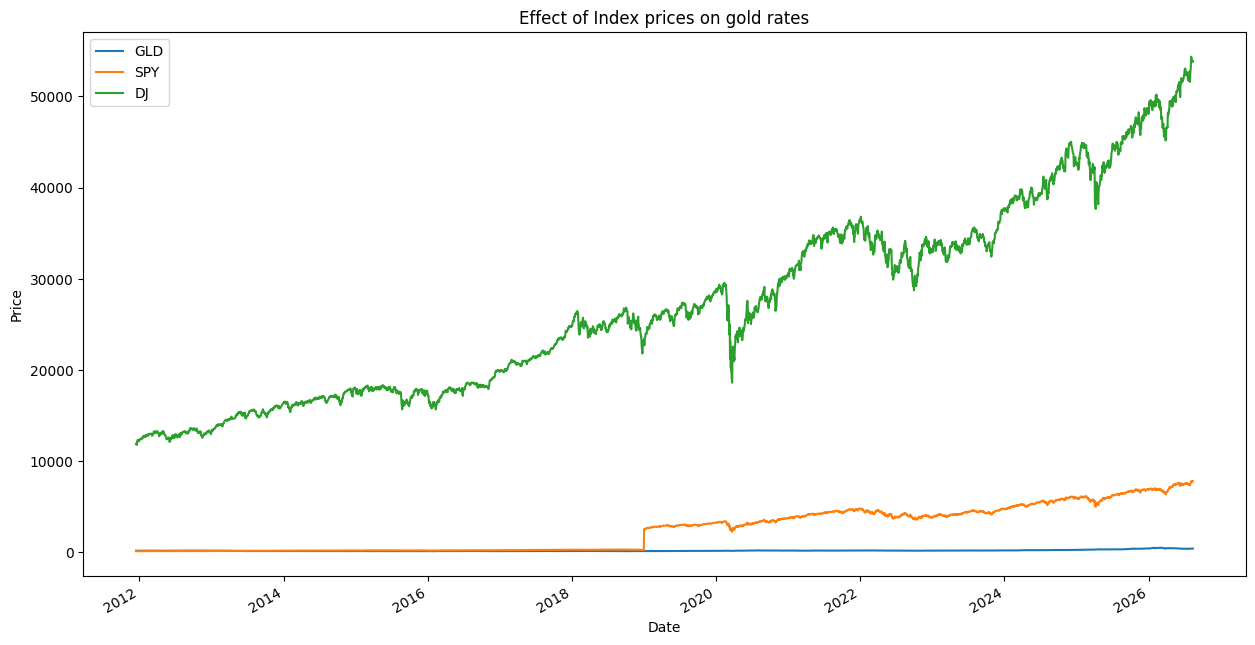

In [8]:
GLD_adj_close = df_final['Adj Close']
SPY_adj_close = df_final['SP_Ajclose']
DJ_adj_close  = df_final['DJ_Ajclose']

df_p = pd.DataFrame({'GLD':GLD_adj_close, 'SPY':SPY_adj_close, 'DJ':DJ_adj_close})

df_ax = df_p.plot(title='Effect of Index prices on gold rates',figsize=(15,8))

df_ax.set_ylabel('Price')
df_ax.legend(loc='upper left')
plt.show()

## Computing Daily Returns of all Features

In [9]:
def compute_daily_returns(df):
    """Compute and return the daily return values."""
    # TODO: Your code here
    # Note: Returned DataFrame must have the same number of rows
    daily_return = (df / df.shift(1)) - 1
    daily_return[0] = 0
    return daily_return


C:\Users\Isfar\AppData\Local\Temp\ipykernel_13848\763627571.py:6: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  daily_return[0] = 0


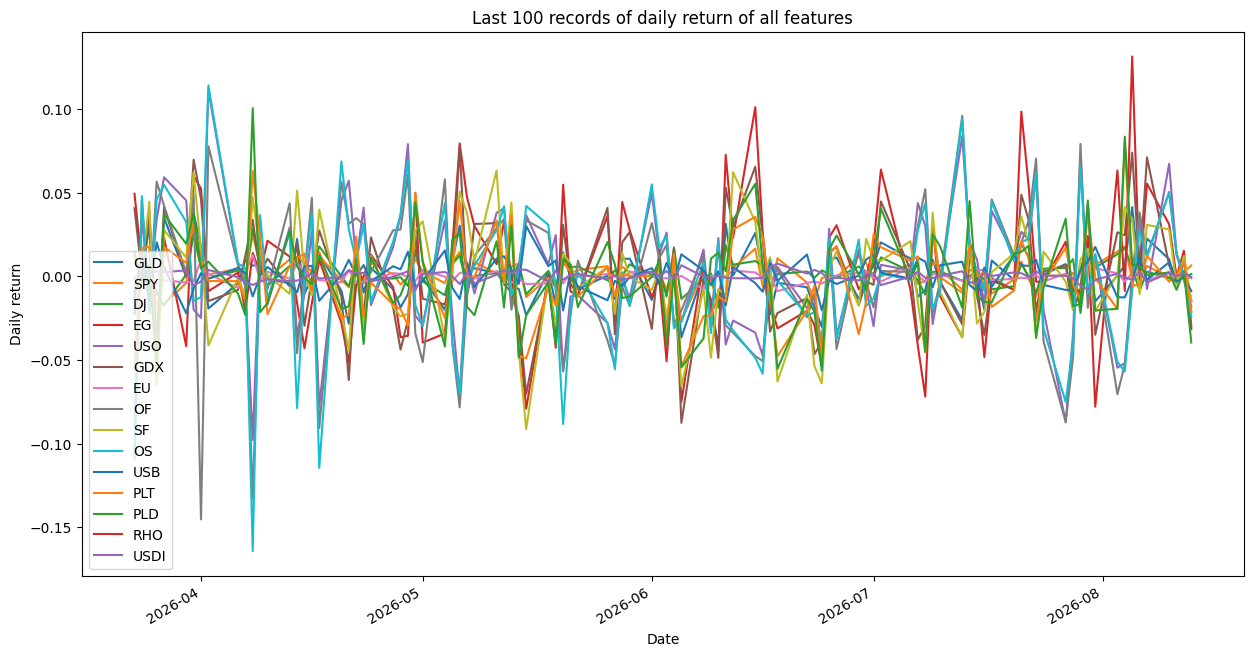

In [10]:
GLD_adj_close = df_final['Adj Close']
SPY_adj_close = df_final['SP_Ajclose']
DJ_adj_close  = df_final['DJ_Ajclose']
EG_adj_close =  df_final['EG_Ajclose']
USO_Adj_close = df_final['USO_Adj Close']
GDX_Adj_close = df_final['GDX_Adj Close']
EU_price      = df_final['EU_Price']
OF_price      = df_final['OF_Price']
OS_price      = df_final['OS_Price']
SF_price      = df_final['SF_Price']
USB_price      = df_final['USB_Price']
PLT_price      = df_final['PLT_Price']
PLD_price      = df_final['PLD_Price']
rho_price      = df_final['RHO_PRICE']
usdi_price      = df_final['USDI_Price']



GLD_daily_return = compute_daily_returns(GLD_adj_close)
SPY_daily_return = compute_daily_returns(SPY_adj_close)
DJ_adj_return    = compute_daily_returns(DJ_adj_close)
EG_adj_return     = compute_daily_returns(EG_adj_close)
USO_Adj_return    = compute_daily_returns(USO_Adj_close)
GDX_Adj_return   =compute_daily_returns(GDX_Adj_close)
EU_return        = compute_daily_returns(EU_price)
OF_price         =compute_daily_returns(OF_price)
OS_price         =compute_daily_returns(OS_price)
SF_price         =compute_daily_returns(SF_price)
USB_price         =compute_daily_returns(USB_price)
PLT_price         =compute_daily_returns(PLT_price)
PLD_price         =compute_daily_returns(PLD_price)
rho_price         =compute_daily_returns(rho_price)
USDI_price         =compute_daily_returns(usdi_price)

df_d = pd.DataFrame({'GLD':GLD_daily_return, 'SPY':SPY_daily_return, 'DJ':DJ_adj_return, 'EG':EG_adj_return, 'USO':USO_Adj_return,
                  'GDX':GDX_Adj_return,'EU':EU_return, 'OF':OF_price,'SF':SF_price,'OS':OS_price, 'USB':USB_price, 'PLT':PLT_price, 'PLD':PLD_price,
                  'RHO':rho_price,'USDI':USDI_price})

daily_ax = df_d[-100:].plot(title='Last 100 records of daily return of all features',figsize=(15,8))

daily_ax.set_ylabel('Daily return')
daily_ax.legend(loc='lower left')
plt.show()

## Computing daily returns of stock indexes

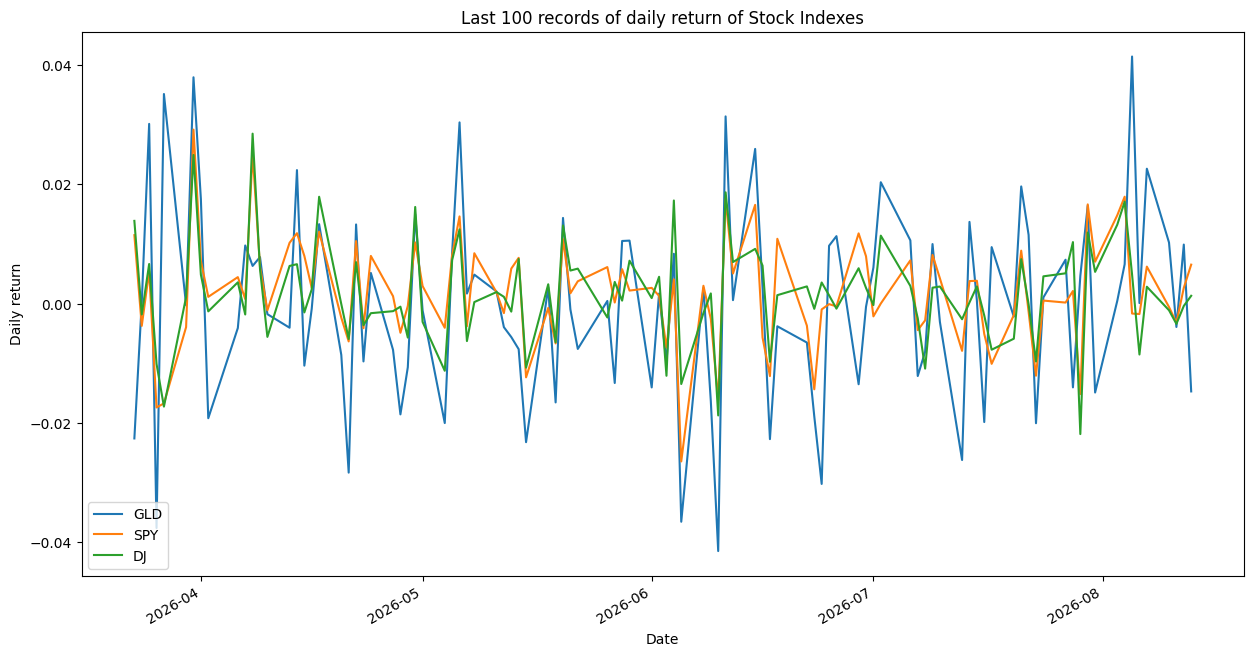

In [11]:
df_s = pd.DataFrame({'GLD':GLD_daily_return, 'SPY':SPY_daily_return, 'DJ':DJ_adj_return})

daily_ax = df_s[-100:].plot(title='Last 100 records of daily return of Stock Indexes',figsize=(15,8))

daily_ax.set_ylabel('Daily return')
daily_ax.legend(loc='lower left')
plt.show()

## Scatterplot

<Axes: xlabel='SPY', ylabel='GLD'>

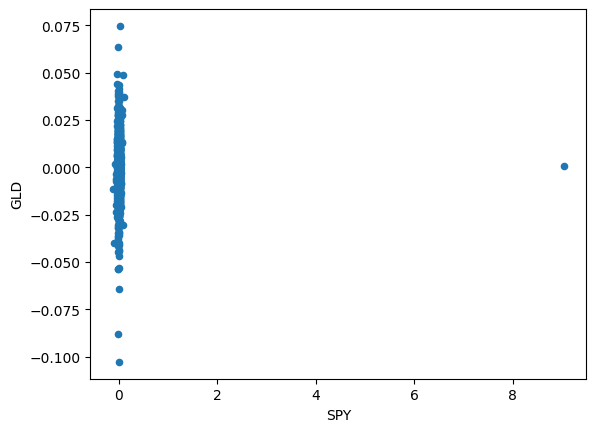

In [12]:
df_d.plot(kind='scatter', x='SPY', y='GLD')

<Axes: xlabel='DJ', ylabel='GLD'>

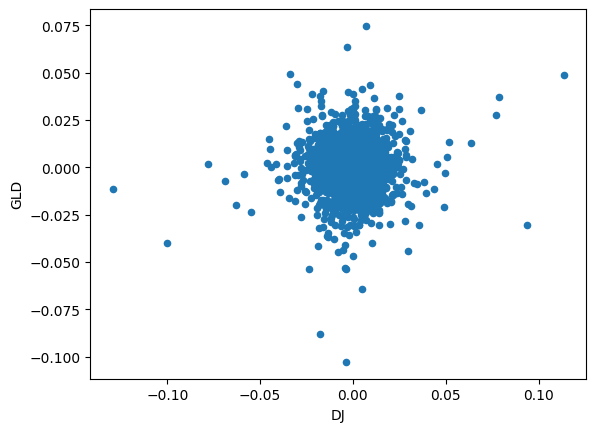

In [13]:
df_d.plot(kind='scatter', x='DJ', y='GLD')

<Axes: xlabel='EG', ylabel='GLD'>

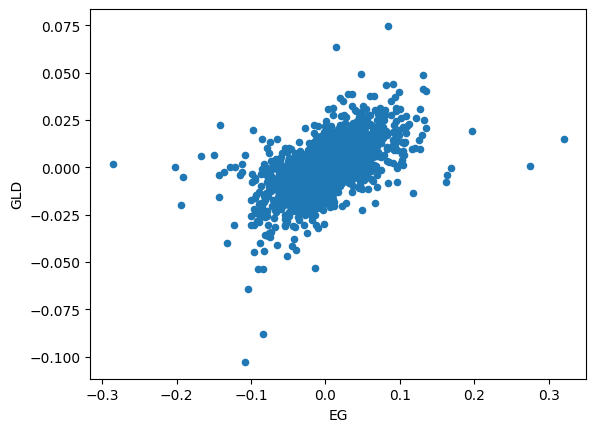

In [14]:
df_d.plot(kind='scatter', x='EG', y='GLD')

<Axes: xlabel='USO', ylabel='GLD'>

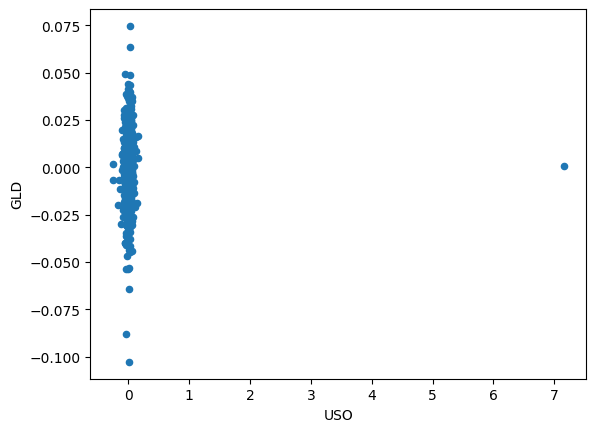

In [15]:
df_d.plot(kind='scatter', x='USO', y='GLD')

<Axes: xlabel='USB', ylabel='GLD'>

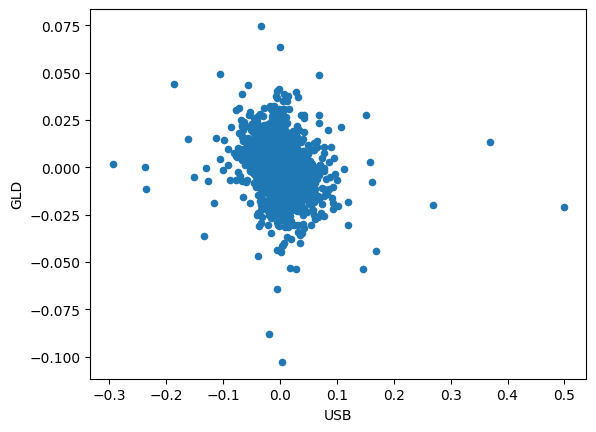

In [16]:
df_d.plot(kind='scatter', x='USB', y='GLD')

<Axes: xlabel='EU', ylabel='GLD'>

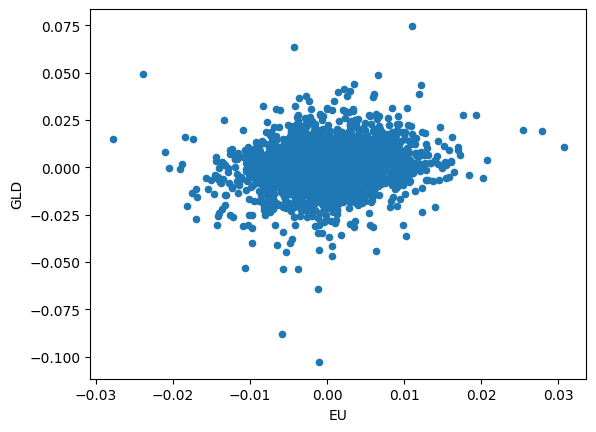

In [17]:
df_d.plot(kind='scatter', x='EU', y='GLD')

<Axes: xlabel='PLT', ylabel='GLD'>

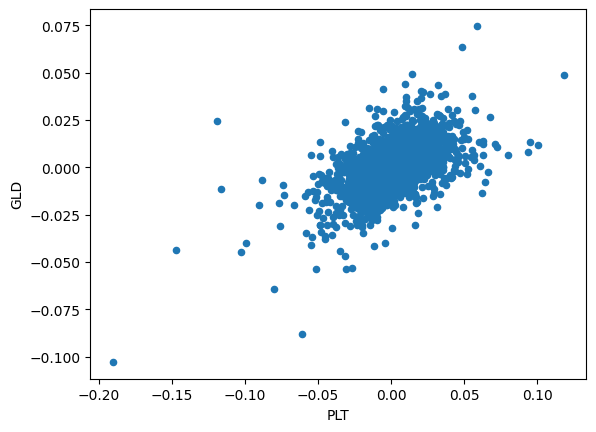

In [18]:
df_d.plot(kind='scatter', x='PLT', y='GLD')

<Axes: xlabel='PLD', ylabel='GLD'>

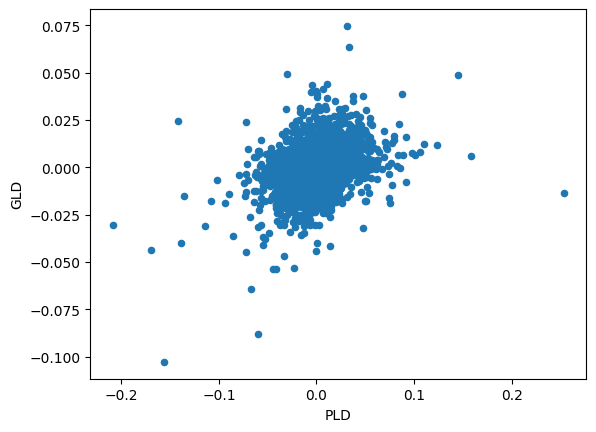

In [19]:
df_d.plot(kind='scatter', x='PLD', y='GLD')

## Statistical Measures (Mean, Standard deviation, Kurtosis)

**Kurtosis** is a statistical measure that is used to describe the distribution. Whereas skewness differentiates extreme values in one versus the other tail, kurtosis measures extreme values in either tail. Distributions with large kurtosis exhibit tail data exceeding the tails of the normal distribution (e.g., five or more standard deviations from the mean). Distributions with low kurtosis exhibit tail data that is generally less extreme than the tails of the normal distribution.


For investors, high kurtosis of the return distribution implies that the investor will experience occasional extreme returns (either positive or negative), more extreme than the usual + or - three standard deviations from the mean that is predicted by the normal distribution of returns. This phenomenon is known as **kurtosis risk**.

**Positive Kurtosis**
More weights in the tail

**Negative Kurtosis**
It has as much data in each tail as it does in the peak.


Mean= 0.00031972790016679403
Standard Deviation= 0.010433909682759196
Kurtosis= 7.406392110092085


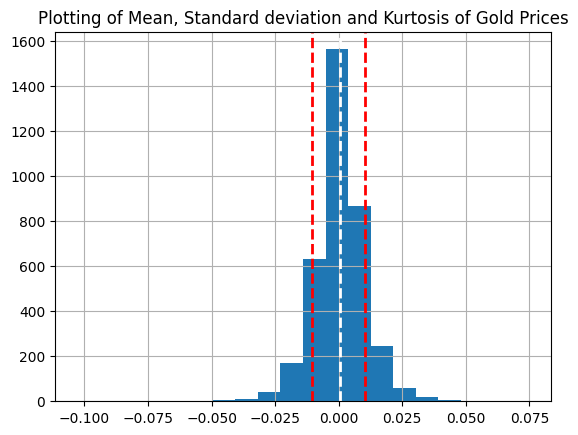

In [20]:
# computing mean,standard deviation and kurtosis of Gold ETF daily return

mean=df_d['GLD'].mean()
# computing standard deviation of Gold stock
std=df_d['GLD'].std()
kurt=df_d['GLD'].kurtosis()
print('Mean=',mean)
print('Standard Deviation=',std)
print('Kurtosis=',kurt)
#Plotting Histogram
df_d['GLD'].hist(bins=20)

plt.axvline(mean, color='w',linestyle='dashed',linewidth=2)
plt.axvline(std, color='r',linestyle='dashed',linewidth=2)
plt.axvline(-std, color='r',linestyle='dashed',linewidth=2)
plt.title("Plotting of Mean, Standard deviation and Kurtosis of Gold Prices")
plt.show()

Mean= 0.0030958694425369934
Standard Deviation= 0.15041895695991303
Kurtosis= 3596.1533799537547


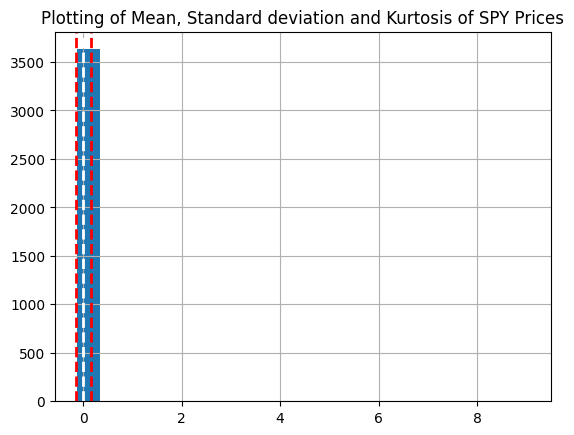

In [21]:
# computing mean,standard deviation and kurtosis of S&P 500 Index daily return

mean=df_d['SPY'].mean()
# computing standard deviation of Gold stock
std=df_d['SPY'].std()
kurt=df_d['SPY'].kurtosis()
print('Mean=',mean)
print('Standard Deviation=',std)
print('Kurtosis=',kurt)
#Plotting Histogram
df_d['SPY'].hist(bins=20)

plt.axvline(mean, color='w',linestyle='dashed',linewidth=2)
plt.axvline(std, color='r',linestyle='dashed',linewidth=2)
plt.axvline(-std, color='r',linestyle='dashed',linewidth=2)
plt.title("Plotting of Mean, Standard deviation and Kurtosis of SPY Prices")
plt.show()

Mean= 0.00046945180068919064
Standard Deviation= 0.010282079065820977
Kurtosis= 20.983628397676526


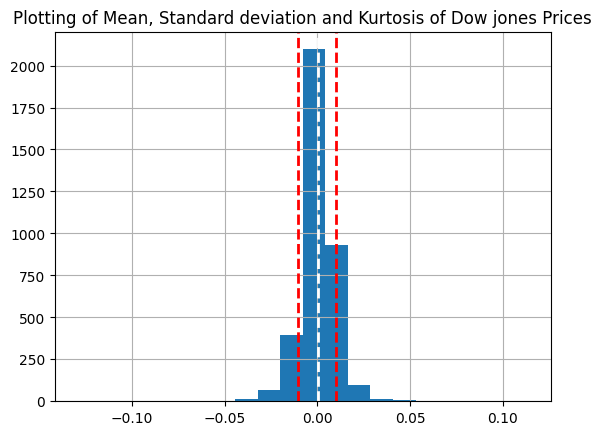

In [22]:
# computing mean,standard deviation and kurtosis of Dow Jones Index daily return
mean=df_d['DJ'].mean()
# computing standard deviation of Gold stock
std=df_d['DJ'].std()
kurt=df_d['DJ'].kurtosis()
print('Mean=',mean)
print('Standard Deviation=',std)
print('Kurtosis=',kurt)
#Plotting Histogram
df_d['DJ'].hist(bins=20)

plt.axvline(mean, color='w',linestyle='dashed',linewidth=2)
plt.axvline(std, color='r',linestyle='dashed',linewidth=2)
plt.axvline(-std, color='r',linestyle='dashed',linewidth=2)
plt.title("Plotting of Mean, Standard deviation and Kurtosis of Dow jones Prices")
plt.show()

## Correlation Analysis

### Plotting Correlation Matrix

<Axes: >

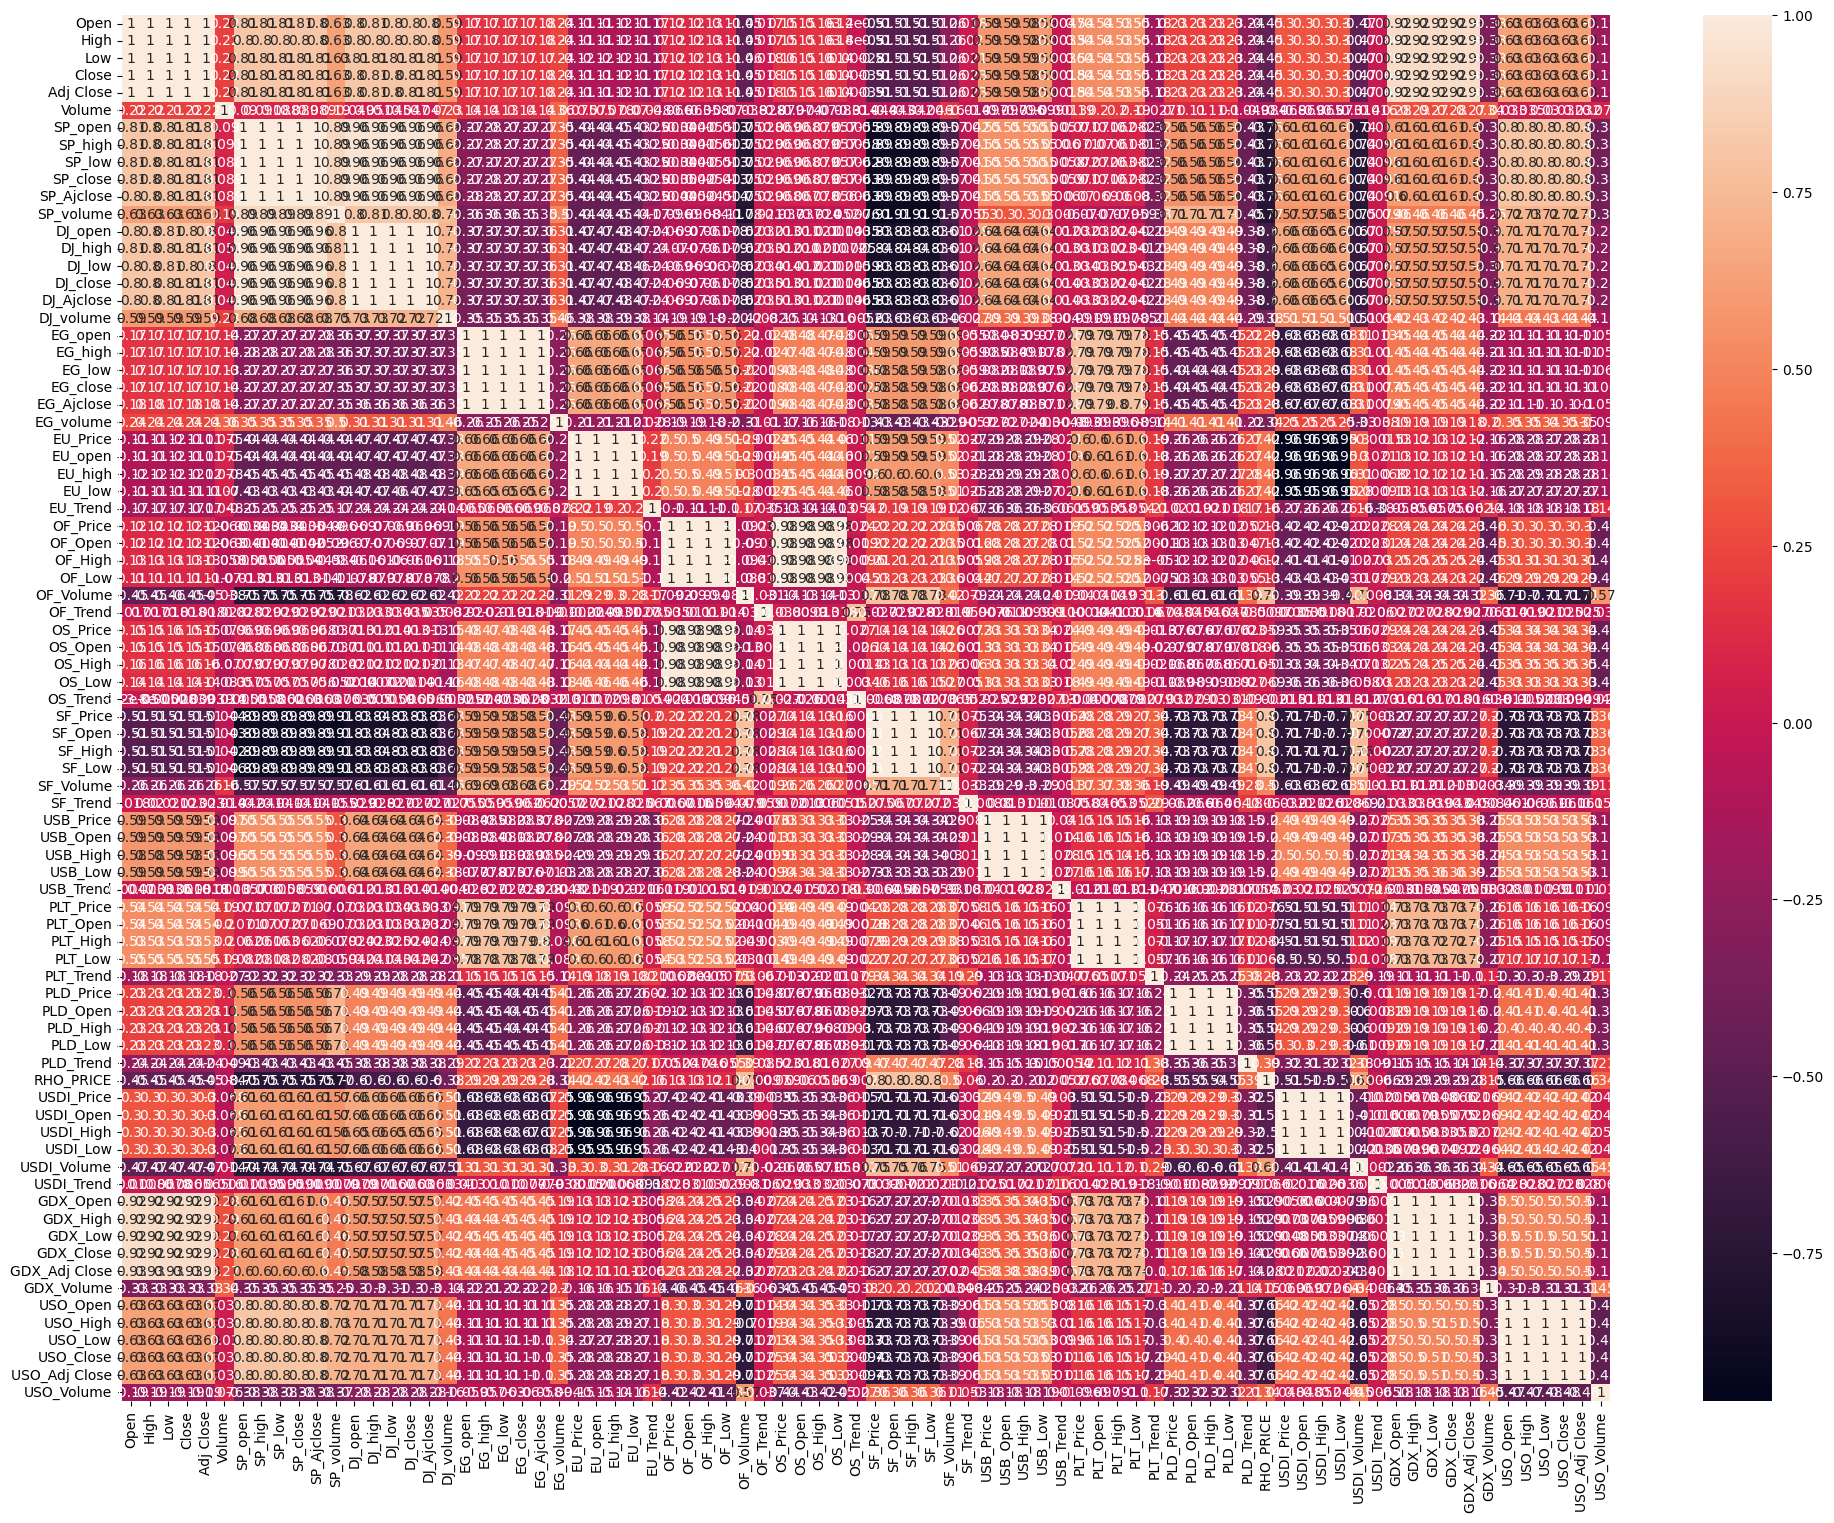

In [23]:
plt.figure(figsize=(24,18)) 
sns.heatmap(df_final.corr(), annot=True) 

In [24]:
X=df_final.drop(['Adj Close'],axis=1)
X=X.drop(['Close'],axis=1)

<Axes: title={'center': 'Correlation with Adj Close'}>

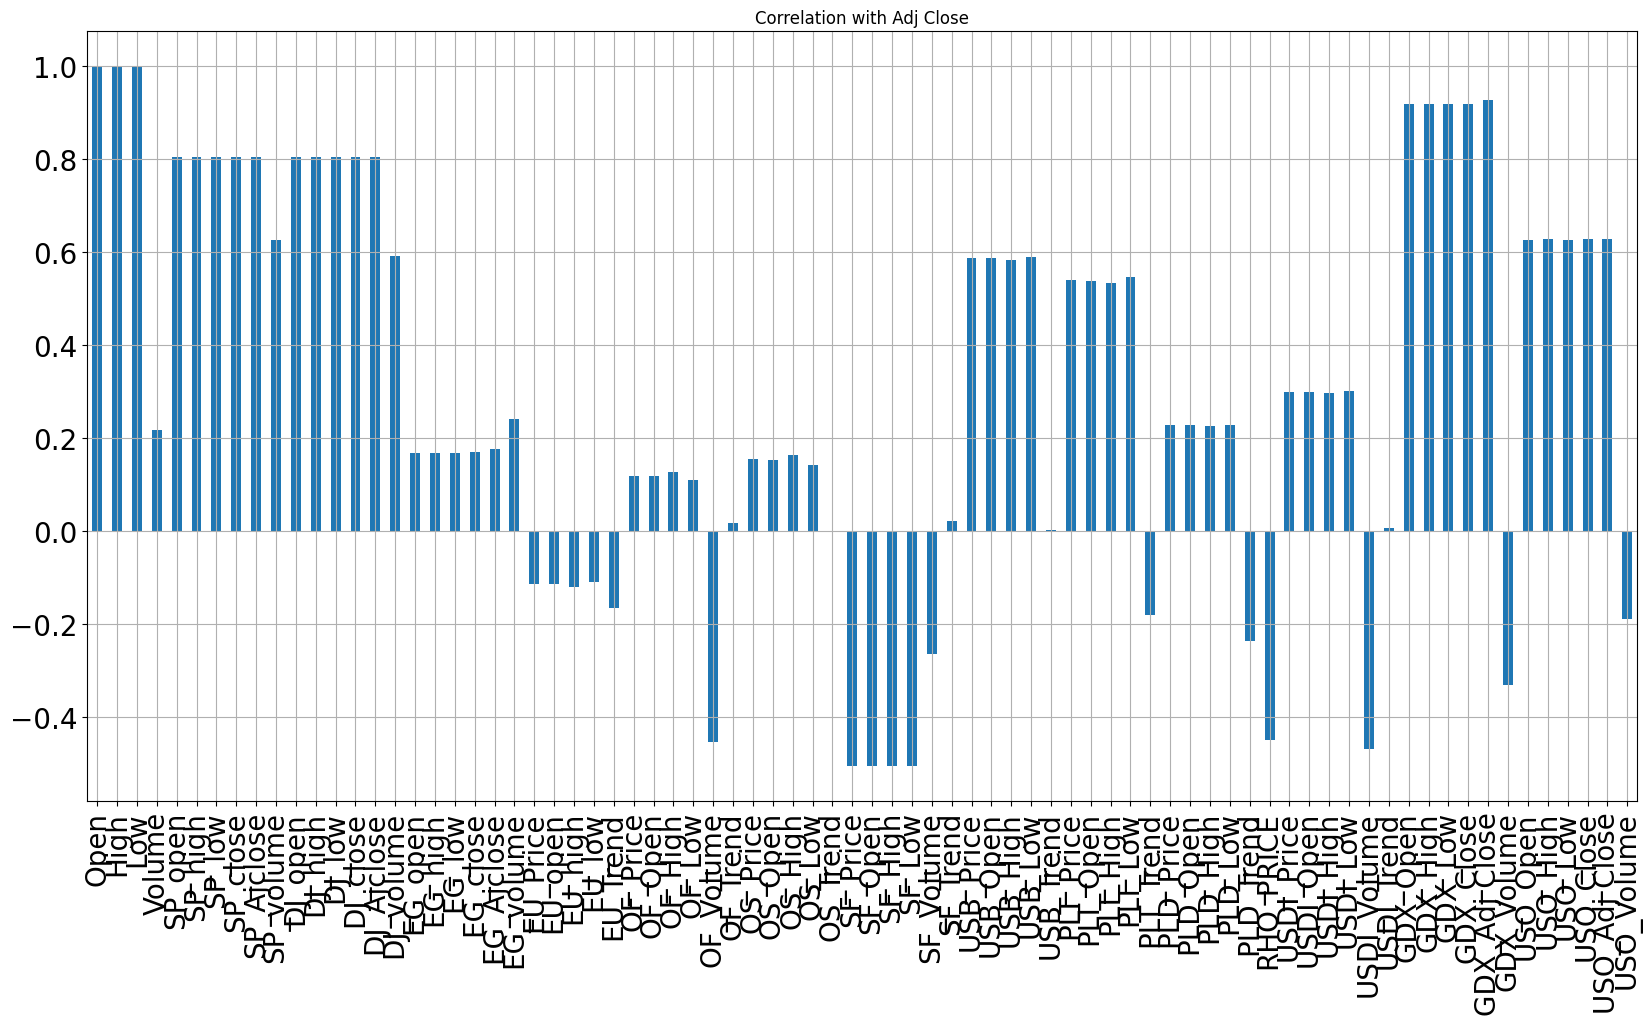

In [25]:
X.corrwith(df_final['Adj Close']).plot.bar(
        figsize = (20, 10), title = "Correlation with Adj Close", fontsize = 20,
        rot = 90, grid = True)

In [26]:
corr_matrix=df_final.corr()
coef=corr_matrix["Adj Close"].sort_values(ascending=False)

### Positively Correlated Variables

In [27]:
pos_corr=coef[coef>0]
pos_corr

Close         1.000000
Adj Close     1.000000
High          0.999904
Low           0.999890
Open          0.999819
                ...   
SF_Trend      0.022554
OF_Trend      0.017956
USDI_Trend    0.006519
USB_Trend     0.001833
OS_Trend      0.000388
Name: Adj Close, Length: 63, dtype: float64

### Negatively Correlated Variables

In [28]:
neg_corr=coef[coef<0]
neg_corr

EU_low        -0.109655
EU_Price      -0.114435
EU_open       -0.114697
EU_high       -0.119273
EU_Trend      -0.166250
PLT_Trend     -0.180312
USO_Volume    -0.188881
PLD_Trend     -0.237210
SF_Volume     -0.263486
GDX_Volume    -0.330001
RHO_PRICE     -0.448814
OF_Volume     -0.454459
USDI_Volume   -0.469008
SF_Open       -0.505940
SF_High       -0.505941
SF_Price      -0.506000
SF_Low        -0.506182
Name: Adj Close, dtype: float64

## Technical Indicators

I will also use following technical indicators which I feel help as a feature for prediction of Gold price

**1. MACD :** The moving average convergence-divergence (MACD) is one of the most powerful and well-known indicators in technical analysis. The indicator is comprised of two exponential moving averages that help measure momentum in a security. The MACD is simply the difference between these two moving averages plotted against a centerline, where the centerline is the point at which the two moving averages are equal.

**2. RSI :** The relative strength index (RSI) is another well known momentum indicators that’s widely used in technical analysis. The indicator is commonly used to identify overbought and oversold conditions in a security with a range between 0 (oversold) and 100 (overbought).

**3. Simple Moving Average (SMA) :** simply takes the sum of all of the past closing prices over a time period and divides the result by the total number of prices used in the calculation. For example, a 10-day simple moving average takes the last ten closing prices and divides them by ten.

**4. Upper Band**

**5. Lower Band**

**6. DIFF**

**7. Open-Close**

**8. High-Low**

In [29]:
def calculate_MACD(df, nslow=26, nfast=12):
    emaslow = df.ewm(span=nslow, min_periods=nslow, adjust=True, ignore_na=False).mean()
    emafast = df.ewm(span=nfast, min_periods=nfast, adjust=True, ignore_na=False).mean()
    dif = emafast - emaslow
    MACD = dif.ewm(span=9, min_periods=9, adjust=True, ignore_na=False).mean()
    return dif, MACD

def calculate_RSI(df, periods=14):
    # wilder's RSI
    delta = df.diff()
    up, down = delta.copy(), delta.copy()

    up[up < 0] = 0
    down[down > 0] = 0

    rUp = up.ewm(com=periods,adjust=False).mean()
    rDown = down.ewm(com=periods, adjust=False).mean().abs()

    rsi = 100 - 100 / (1 + rUp / rDown)
    return rsi

def calculate_SMA(df, peroids=15):
    SMA = df.rolling(window=peroids, min_periods=peroids, center=False).mean()
    return SMA

def calculate_BB(df, peroids=15):
    STD = df.rolling(window=peroids,min_periods=peroids, center=False).std()
    SMA = calculate_SMA(df)
    upper_band = SMA + (2 * STD)
    lower_band = SMA - (2 * STD)
    return upper_band, lower_band

def calculate_stdev(df,periods=5):
    STDEV = df.rolling(periods).std()
    return STDEV

## Plotting Technical Indicators

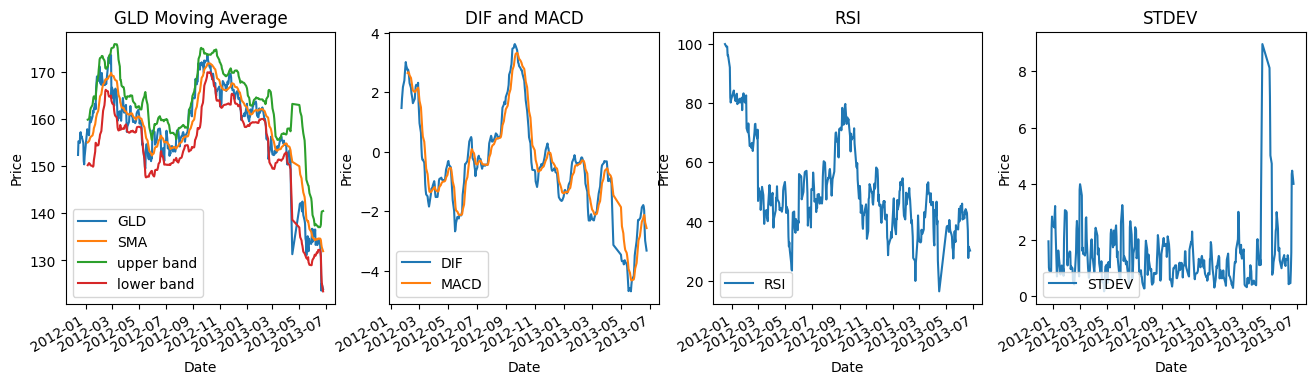

In [30]:
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4))

# Calculate Simple Moving Average for GLD
SMA_GLD = calculate_SMA(GLD_adj_close)

GLD_adj_close[:365].plot(title='GLD Moving Average',label='GLD', ax=axes[0])

SMA_GLD[:365].plot(label="SMA",ax=axes[0])


# Calculate Bollinger Bands for GLD
upper_band, lower_band = calculate_BB(GLD_adj_close)

upper_band[:365].plot(label='upper band', ax=axes[0])
lower_band[:365].plot(label='lower band', ax=axes[0])


# Calculate MACD for GLD
DIF, MACD = calculate_MACD(GLD_adj_close)

DIF[:365].plot(title='DIF and MACD',label='DIF', ax=axes[1])
MACD[:365].plot(label='MACD', ax=axes[1])

# Calculate RSI for GLD
RSI = calculate_RSI(GLD_adj_close)
RSI[:365].plot(title='RSI',label='RSI', ax=axes[2])

# Calculating Standard deviation for GLD
STDEV= calculate_stdev(GLD_adj_close)
STDEV[:365].plot(title='STDEV',label='STDEV', ax=axes[3])

Open_Close=df_final.Open - df_final.Close

High_Low=df_final.High-df_final.Low

axes[0].set_ylabel('Price')
axes[1].set_ylabel('Price')
axes[2].set_ylabel('Price')
axes[3].set_ylabel('Price')



axes[0].legend(loc='lower left')
axes[1].legend(loc='lower left')
axes[2].legend(loc='lower left')
axes[3].legend(loc='lower left')

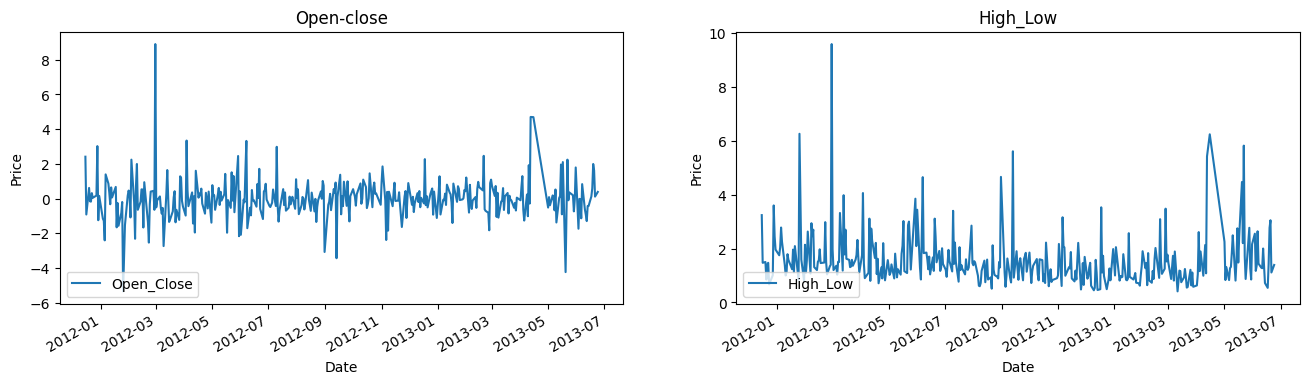

In [31]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 4))
Open_Close=df_final.Open - df_final.Close
Open_Close[:365].plot(title='Open-close',label='Open_Close', ax=axes[0])

High_Low=df_final.High-df_final.Low
High_Low[:365].plot(title='High_Low',label='High_Low', ax=axes[1])
axes[0].set_ylabel('Price')
axes[1].set_ylabel('Price')




axes[0].legend(loc='lower left')
axes[1].legend(loc='lower left')


In [32]:
test = df_final
test['SMA'] = SMA_GLD
test['Upper_band'] = upper_band
test['Lower_band'] = lower_band
test['DIF'] = DIF
test['MACD'] = MACD
test['RSI'] = RSI
test['STDEV'] = STDEV
test['Open_Close']=Open_Close
test['High_Low']=High_Low


# Dropping first 33 records from the data as it has null values because of introduction of technical indicators
test = test[33:]

# Target column
target_adj_close = pd.DataFrame(test['Adj Close'])


display(test.head())

,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,SP_close,...,USO_Volume,SMA,Upper_band,Lower_band,DIF,MACD,RSI,STDEV,Open_Close,High_Low
Date,,,,,,,,,,,,,,,,,,,,,
2012-02-06,166.960007,167.679993,166.610001,167.179993,167.179993,8807400,133.979996,134.509995,133.830002,134.449997,...,6126100,165.198666,173.018365,157.378968,2.724443,2.641891,70.144545,1.562107,-0.219986,1.069992
2012-02-07,167.380005,170.089996,167.149994,169.699997,169.699997,11614300,134.169998,135.020004,133.639999,134.789993,...,10237000,165.894667,173.296304,158.493029,2.754381,2.667095,73.152763,1.594111,-2.319992,2.940002
2012-02-08,169.259995,169.960007,167.500000,168.500000,168.500000,10655500,134.860001,135.220001,134.309998,135.190002,...,9045800,166.428000,173.297467,159.558533,2.655845,2.664634,69.576023,1.575718,0.759995,2.460007
2012-02-09,170.009995,170.369995,167.669998,168.020004,168.020004,16085200,135.410004,135.589996,134.559998,135.360001,...,4663500,166.856000,173.217507,160.494493,2.511947,2.631843,68.148015,0.965153,1.989991,2.699997
2012-02-10,166.490005,167.639999,166.330002,167.139999,167.139999,10326800,134.160004,134.470001,133.839996,134.360001,...,6008600,167.250666,172.795817,161.705515,2.303734,2.562404,65.507009,1.059963,-0.649994,1.309997


In [33]:
df_final.columns

Index(['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'SP_open',
       'SP_high', 'SP_low', 'SP_close', 'SP_Ajclose', 'SP_volume', 'DJ_open',
       'DJ_high', 'DJ_low', 'DJ_close', 'DJ_Ajclose', 'DJ_volume', 'EG_open',
       'EG_high', 'EG_low', 'EG_close', 'EG_Ajclose', 'EG_volume', 'EU_Price',
       'EU_open', 'EU_high', 'EU_low', 'EU_Trend', 'OF_Price', 'OF_Open',
       'OF_High', 'OF_Low', 'OF_Volume', 'OF_Trend', 'OS_Price', 'OS_Open',
       'OS_High', 'OS_Low', 'OS_Trend', 'SF_Price', 'SF_Open', 'SF_High',
       'SF_Low', 'SF_Volume', 'SF_Trend', 'USB_Price', 'USB_Open', 'USB_High',
       'USB_Low', 'USB_Trend', 'PLT_Price', 'PLT_Open', 'PLT_High', 'PLT_Low',
       'PLT_Trend', 'PLD_Price', 'PLD_Open', 'PLD_High', 'PLD_Low',
       'PLD_Trend', 'RHO_PRICE', 'USDI_Price', 'USDI_Open', 'USDI_High',
       'USDI_Low', 'USDI_Volume', 'USDI_Trend', 'GDX_Open', 'GDX_High',
       'GDX_Low', 'GDX_Close', 'GDX_Adj Close', 'GDX_Volume', 'USO_Open',
       'USO_High', 'USO

In [34]:
# selecting Feature Columns
feature_columns = ['Open', 'High', 'Low', 'Volume','SP_open','SP_high','SP_low','SP_Ajclose','SP_volume','DJ_open','DJ_high', 'DJ_low',  'DJ_Ajclose', 'DJ_volume', 'EG_open','EG_high', 'EG_low',  
                   'EG_Ajclose', 'EG_volume', 'EU_Price','EU_open', 'EU_high', 'EU_low', 'EU_Trend', 'OF_Price','OF_Open','OF_High', 'OF_Low', 'OF_Volume', 'OF_Trend', 'OS_Price', 'OS_Open','OS_High', 'OS_Low', 'OS_Trend', 'SF_Price', 'SF_Open', 'SF_High',
                   'SF_Low', 'SF_Volume', 'SF_Trend', 'USB_Price', 'USB_Open', 'USB_High','USB_Low', 'USB_Trend', 'PLT_Price', 'PLT_Open', 'PLT_High', 'PLT_Low',
                    'PLT_Trend', 'PLD_Price', 'PLD_Open', 'PLD_High', 'PLD_Low','PLD_Trend', 'RHO_PRICE', 'USDI_Price', 'USDI_Open', 'USDI_High',
                     'USDI_Low', 'USDI_Volume', 'USDI_Trend','GDX_Open', 'GDX_High',
       'GDX_Low', 'GDX_Close', 'GDX_Adj Close', 'GDX_Volume', 'USO_Open',
       'USO_High', 'USO_Low', 'USO_Close', 'USO_Adj Close', 'USO_Volume','SMA', 'Upper_band', 'Lower_band', 'DIF', 'MACD','RSI','STDEV','Open_Close', 'High_Low']



## Normalizing the data

Perform feature scaling/normalization of feature variables using sklearn's MinMaxScaler function.

In [35]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
feature_minmax_transform_data = scaler.fit_transform(test[feature_columns])
feature_minmax_transform = pd.DataFrame(columns=feature_columns, data=feature_minmax_transform_data, index=test.index)
feature_minmax_transform.head()

,Open,High,Low,Volume,SP_open,SP_high,SP_low,SP_Ajclose,SP_volume,DJ_open,...,USO_Volume,SMA,Upper_band,Lower_band,DIF,MACD,RSI,STDEV,Open_Close,High_Low
Date,,,,,,,,,,,,,,,,,,,,,
2012-02-06,0.161629,0.163172,0.173293,0.079800,0.000802,0.000751,0.000876,0.000654,0.010742,0.017947,...,0.039726,0.169177,0.172713,0.159130,0.469324,0.496636,0.752948,0.048728,0.360666,0.020986
2012-02-07,0.162657,0.169069,0.174703,0.110188,0.000827,0.000817,0.000851,0.000692,0.013518,0.017561,...,0.068406,0.171044,0.173406,0.162209,0.470141,0.497562,0.795049,0.049773,0.298278,0.066618
2012-02-08,0.167258,0.168750,0.175617,0.099808,0.000917,0.000843,0.000939,0.000738,0.013900,0.018067,...,0.060095,0.172475,0.173409,0.165154,0.467453,0.497471,0.744992,0.049173,0.389780,0.054905
2012-02-09,0.169094,0.169754,0.176061,0.158591,0.000989,0.000891,0.000972,0.000757,0.014822,0.018507,...,0.029523,0.173624,0.173209,0.167741,0.463528,0.496267,0.725006,0.029228,0.426322,0.060761
2012-02-10,0.160479,0.163074,0.172562,0.096249,0.000826,0.000745,0.000877,0.000644,0.016748,0.018629,...,0.038906,0.174683,0.172159,0.171088,0.457848,0.493716,0.688044,0.032325,0.347891,0.026842


In [36]:
display(feature_minmax_transform.head())
print('Shape of features : ', feature_minmax_transform.shape)
print('Shape of target : ', target_adj_close.shape)

# Shift target array because we want to predict the n + 1 day value


target_adj_close = target_adj_close.shift(-1)
validation_y = target_adj_close[-90:-1]
target_adj_close = target_adj_close[:-90]

# Taking last 90 rows of data to be validation set
validation_X = feature_minmax_transform[-90:-1]
feature_minmax_transform = feature_minmax_transform[:-90]
display(validation_X.tail())
display(validation_y.tail())

print("\n -----After process------ \n")
print('Shape of features : ', feature_minmax_transform.shape)
print('Shape of target : ', target_adj_close.shape)
display(target_adj_close.tail())

,Open,High,Low,Volume,SP_open,SP_high,SP_low,SP_Ajclose,SP_volume,DJ_open,...,USO_Volume,SMA,Upper_band,Lower_band,DIF,MACD,RSI,STDEV,Open_Close,High_Low
Date,,,,,,,,,,,,,,,,,,,,,
2012-02-06,0.161629,0.163172,0.173293,0.079800,0.000802,0.000751,0.000876,0.000654,0.010742,0.017947,...,0.039726,0.169177,0.172713,0.159130,0.469324,0.496636,0.752948,0.048728,0.360666,0.020986
2012-02-07,0.162657,0.169069,0.174703,0.110188,0.000827,0.000817,0.000851,0.000692,0.013518,0.017561,...,0.068406,0.171044,0.173406,0.162209,0.470141,0.497562,0.795049,0.049773,0.298278,0.066618
2012-02-08,0.167258,0.168750,0.175617,0.099808,0.000917,0.000843,0.000939,0.000738,0.013900,0.018067,...,0.060095,0.172475,0.173409,0.165154,0.467453,0.497471,0.744992,0.049173,0.389780,0.054905
2012-02-09,0.169094,0.169754,0.176061,0.158591,0.000989,0.000891,0.000972,0.000757,0.014822,0.018507,...,0.029523,0.173624,0.173209,0.167741,0.463528,0.496267,0.725006,0.029228,0.426322,0.060761
2012-02-10,0.160479,0.163074,0.172562,0.096249,0.000826,0.000745,0.000877,0.000644,0.016748,0.018629,...,0.038906,0.174683,0.172159,0.171088,0.457848,0.493716,0.688044,0.032325,0.347891,0.026842


Shape of features :  (3599, 84)
Shape of target :  (3599, 1)


,Open,High,Low,Volume,SP_open,SP_high,SP_low,SP_Ajclose,SP_volume,DJ_open,...,USO_Volume,SMA,Upper_band,Lower_band,DIF,MACD,RSI,STDEV,Open_Close,High_Low
Date,,,,,,,,,,,,,,,,,,,,,
2026-08-06,0.706283,0.712314,0.749354,0.103043,0.992434,0.990394,0.991484,0.988418,0.531710,1.000000,...,0.034255,0.731674,0.709029,0.722699,0.396174,0.301235,0.597058,0.307023,0.362151,0.113226
2026-08-07,0.731002,0.733209,0.774625,0.128703,0.995233,0.993025,0.994239,0.994621,0.500704,0.986354,...,0.028456,0.737052,0.724444,0.716670,0.441376,0.333394,0.667173,0.369618,0.400773,0.085407
2026-08-10,0.726376,0.739522,0.771962,0.104154,0.997399,0.994415,0.997372,0.994032,0.486697,0.991632,...,0.033132,0.743302,0.739258,0.713106,0.485117,0.370902,0.695930,0.354080,0.223708,0.173255
2026-08-11,0.740400,0.741455,0.782300,0.064986,0.999462,0.993602,0.993985,0.990791,0.472729,0.989008,...,0.055776,0.747980,0.750060,0.710756,0.514923,0.408936,0.674478,0.200161,0.440880,0.095900
2026-08-12,0.744977,0.749602,0.790993,0.096859,0.999194,0.993407,0.996696,0.993432,0.456239,0.985130,...,0.022190,0.752596,0.761755,0.707285,0.545526,0.447604,0.703584,0.189747,0.378788,0.095900


,Adj Close
Date,
2026-08-06,398.470001
2026-08-07,402.540009
2026-08-10,400.959991
2026-08-11,404.920013
2026-08-12,398.959991



 -----After process------ 

Shape of features :  (3509, 84)
Shape of target :  (3509, 1)


,Adj Close
Date,
2026-03-30,430.290009
2026-03-31,437.820007
2026-04-01,429.410004
2026-04-02,427.649994
2026-04-06,431.809998


## Train Test Split

Train test split using sklearn's Timeseries split

In [37]:
ts_split= TimeSeriesSplit(n_splits=10)
for train_index, test_index in ts_split.split(feature_minmax_transform):
        X_train, X_test = feature_minmax_transform[:len(train_index)], feature_minmax_transform[len(train_index): (len(train_index)+len(test_index))]
        y_train, y_test = target_adj_close[:len(train_index)].values.ravel(), target_adj_close[len(train_index): (len(train_index)+len(test_index))].values.ravel()
       

In [38]:
X_train.shape

(3190, 84)

In [39]:
X_test.shape

(319, 84)

In [40]:
y_train.shape

(3190,)

In [41]:
y_test.shape

(319,)

In [42]:
def validate_result(model, model_name):
    predicted = model.predict(validation_X)
    RSME_score = np.sqrt(mean_squared_error(validation_y, predicted))
    print('RMSE: ', RSME_score)
    
    R2_score = r2_score(validation_y, predicted)
    print('R2 score: ', R2_score)

    plt.plot(validation_y.index, predicted,'r', label='Predict')
    plt.plot(validation_y.index, validation_y,'b', label='Actual')
    plt.ylabel('Price')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
    plt.title(model_name + ' Predict vs Actual')
    plt.legend(loc='upper right')
    plt.show()

## Model Building

### 1. Benchmark Model :
       I will use Decision Tree Regressor with default parameter as my Benchmark model for the project.

RMSE:  152.140261551601
R2 score:  -35.5064241808531


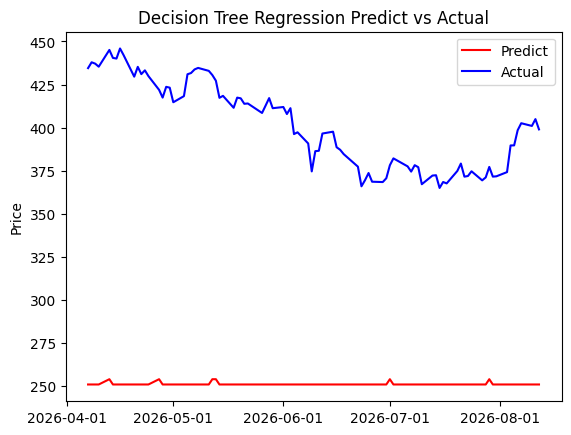

In [43]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=0)

benchmark_dt=dt.fit(X_train, y_train)

validate_result(benchmark_dt, 'Decision Tree Regression')

## Solution Model 

### Support Vector Regressor (SVR)

RMSE:  38.944738929832695
R2 score:  -1.392095820915086


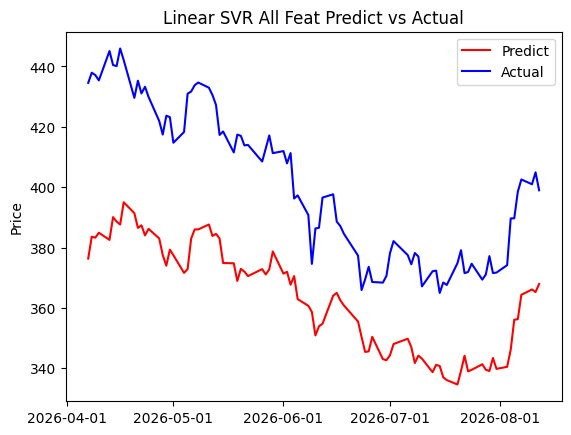

In [44]:
# Save all soultion models
solution_models = {}
# SVR with  linear Kernel
svr_lin = SVR(kernel='linear')
linear_svr_clf_feat = svr_lin.fit(X_train,y_train)
validate_result(linear_svr_clf_feat,'Linear SVR All Feat')


### Hyperparameter Tuning
In this step I will tune two parameters of SVR C and epsilon to see if the model shows any improvement.

RMSE:  6.1882945142006385
R2 score:  0.9396019485550469


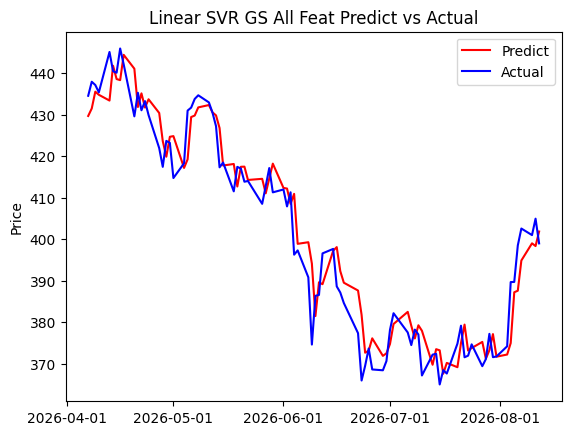

In [45]:
linear_svr_parameters = {
    'C':[0.5, 1.0, 10.0, 50.0],
    'epsilon':[0, 0.1, 0.5, 0.7, 0.9],
}

lsvr_grid_search_feat = GridSearchCV(estimator=linear_svr_clf_feat,
                           param_grid=linear_svr_parameters,
                           cv=ts_split,
)

lsvr_grid_search_feat.fit(X_train, y_train)

validate_result(lsvr_grid_search_feat,'Linear SVR GS All Feat')


In [46]:
solution_models['SVR All Feat'] = lsvr_grid_search_feat

## Solution Model : Random Forest

RMSE:  152.15015513793176
R2 score:  -35.511172315228784


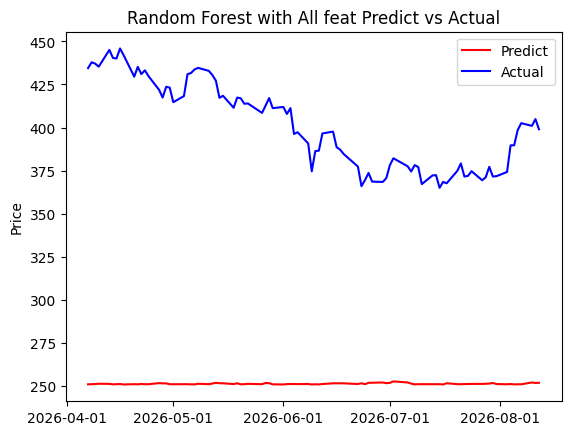

In [47]:
rf_cl = RandomForestRegressor(n_estimators=50, random_state=0)
random_forest_clf_feat = rf_cl.fit(X_train,y_train)
validate_result(random_forest_clf_feat,'Random Forest with All feat')

## Hyper parameter Tuning
In this I will tune 3 parameters of Random forest which are n_estimators, max_features, max_depth

In [48]:
random_forest_parameters = {
    'n_estimators':[10,15,20, 50, 100],
    'max_features':['auto','sqrt','log2'],
    'max_depth':[2, 3, 5, 7,10],
}

grid_search_RF_feat = GridSearchCV(estimator=random_forest_clf_feat,
                           param_grid=random_forest_parameters,
                           cv=ts_split,
)

grid_search_RF_feat.fit(X_train, y_train)


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
250 fits failed out of a total of 750.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
250 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
  File "c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base

,estimator,RandomForestR...andom_state=0)
,param_grid,"{'max_depth': [2, 3, ...], 'max_features': ['auto', 'sqrt', ...], 'n_estimators': [10, 15, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,20


{'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 20}
RMSE:  156.64705137647937
R2 score:  -37.70128877087098


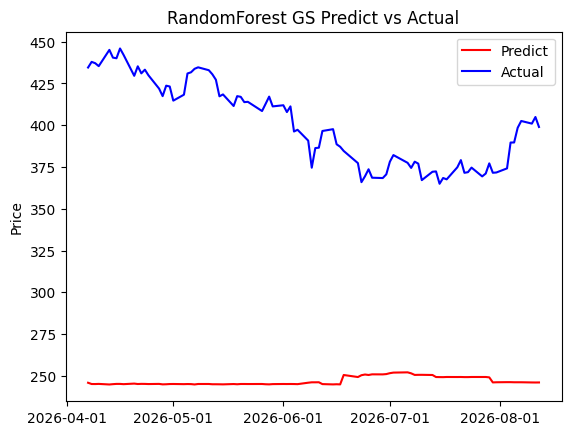

In [49]:
print(grid_search_RF_feat.best_params_)
validate_result(grid_search_RF_feat,'RandomForest GS')

As we have seen, Random forest with default parameters performed better than tuned Random forest model.So, we will include random forest with default parameters as our second solution model.

In [50]:
solution_models['Random_Forest with Feat'] = random_forest_clf_feat

## Solution Model : Lasso and Ridge

c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


RMSE:  6.326249894595488
R2 score:  0.9368790299117905


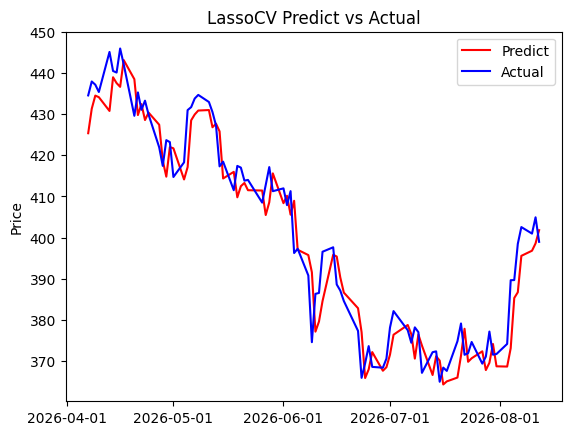

RMSE:  6.5392123329819825
R2 score:  0.9325577800021632


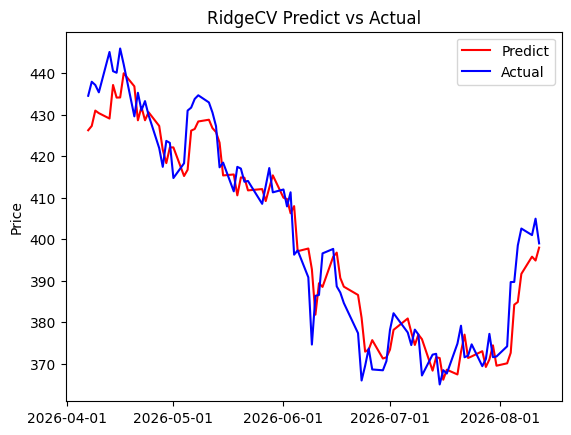

In [51]:
from sklearn.linear_model import LassoCV
from sklearn.linear_model import RidgeCV

lasso_clf = LassoCV(n_alphas=1000, max_iter=3000, random_state=0)
ridge_clf = RidgeCV(gcv_mode='auto')

lasso_clf_feat = lasso_clf.fit(X_train,y_train)
validate_result(lasso_clf_feat,'LassoCV')
solution_models['LassoCV All feat'] = lasso_clf_feat

ridge_clf_feat = ridge_clf.fit(X_train,y_train)
validate_result(ridge_clf_feat,'RidgeCV')
solution_models['RidgeCV All Feat'] = ridge_clf_feat

## Solution Model : Bayesian Ridge

RMSE:  5.918420887027278
R2 score:  0.9447550389172282


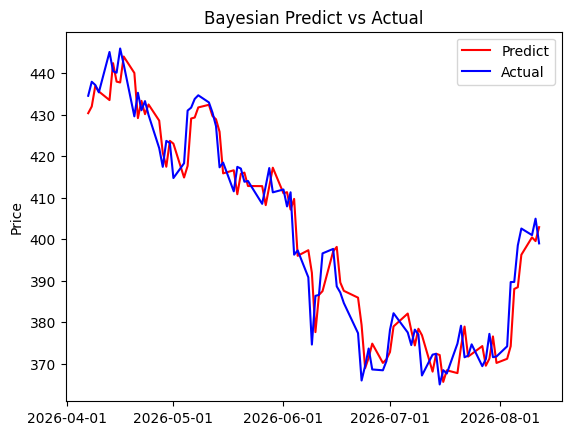

In [52]:
from sklearn import linear_model
bay = linear_model.BayesianRidge()
bay_feat = bay.fit(X_train,y_train)
validate_result(bay_feat,'Bayesian')
solution_models['Bay All Feat'] = bay_feat

## Solution Model : Gradient Boosting Regressor

RMSE:  151.11612426727027
R2 score:  -35.016589973505106


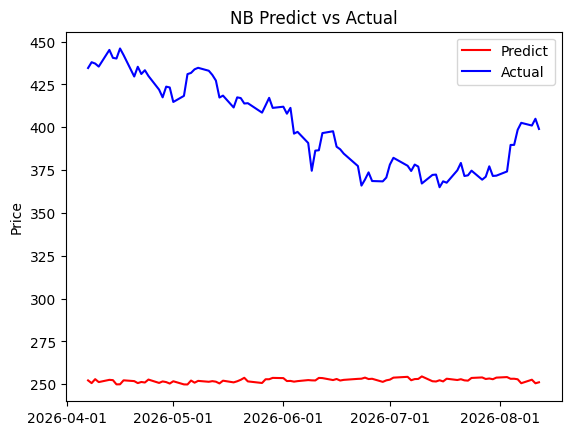

In [53]:
from sklearn.ensemble import GradientBoostingRegressor

regr = GradientBoostingRegressor(
    n_estimators=70,
    learning_rate=0.1,
    max_depth=4,
    random_state=0
)

GB_feat = regr.fit(X_train, y_train)
validate_result(GB_feat, 'NB')
solution_models['GB All Feat'] = GB_feat


## Solution Model : Stochastic Gradient Descent (SGD)

RMSE:  27.58391372810526
R2 score:  -0.2000317878994795


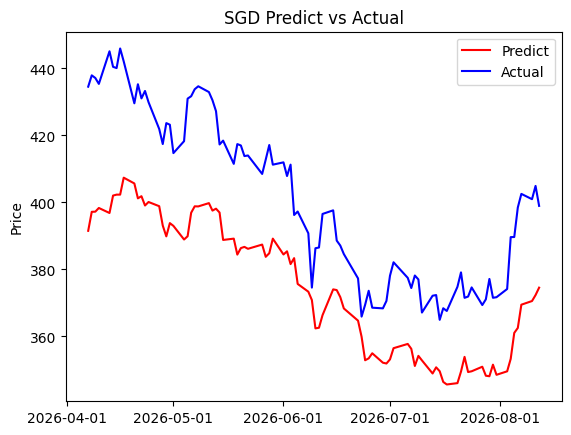

In [54]:
from sklearn.linear_model import SGDRegressor
sgd =SGDRegressor(max_iter=1000, tol=1e-3,loss='squared_epsilon_insensitive',penalty='l1',alpha=0.1)
sgd_feat = sgd.fit(X_train,y_train)
validate_result(sgd_feat,'SGD')
solution_models['SGD All Feat'] = sgd_feat

## Model Review
In this step, we will review benchmark model and all the solution model based on evaluation metrics i.e, RMSE and R2 score

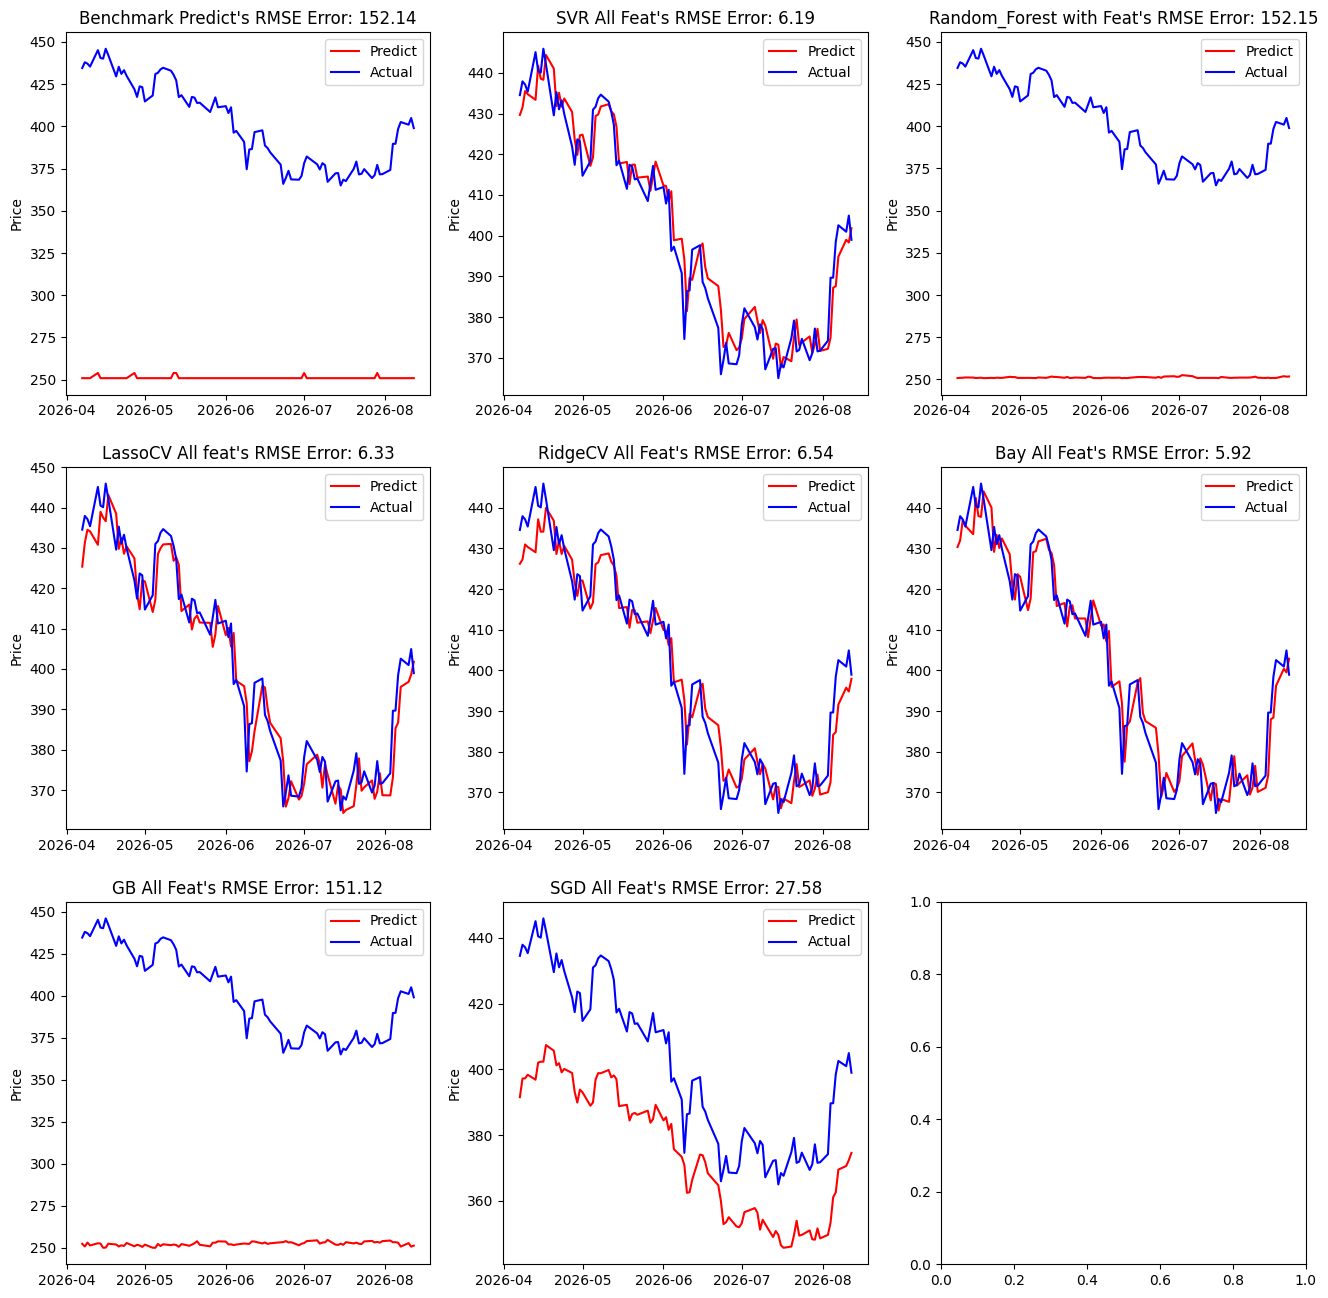

In [55]:
RMSE_scores = {}
def model_review(models):
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16, 16))

    #plot benchmark model
    benchmark_predicted = benchmark_dt.predict(validation_X)
    benchmark_RSME_score = np.sqrt(mean_squared_error(validation_y, benchmark_predicted))
    RMSE_scores['Benchmark'] = benchmark_RSME_score
    
    axes[0,0].plot(validation_y.index, benchmark_predicted,'r', label='Predict')
    axes[0,0].plot(validation_y.index, validation_y,'b', label='Actual')
    axes[0,0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    axes[0,0].xaxis.set_major_locator(mdates.MonthLocator())
    axes[0,0].set_ylabel('Price')
    axes[0,0].set_title("Benchmark Predict's RMSE Error: " +"{0:.2f}".format(benchmark_RSME_score))
    axes[0,0].legend(loc='upper right')
    
    #plot block
    ax_x = 0
    ax_y = 1
    #plot solution model
    for name, model in models.items():
        predicted = model.predict(validation_X)
        RSME_score = np.sqrt(mean_squared_error(validation_y, predicted))

           
        axes[ax_x][ax_y].plot(validation_y.index, predicted,'r', label='Predict')
        axes[ax_x][ax_y].plot(validation_y.index, validation_y,'b', label='Actual')
        axes[ax_x][ax_y].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        axes[ax_x][ax_y].xaxis.set_major_locator(mdates.MonthLocator())
        axes[ax_x][ax_y].set_ylabel('Price')
        axes[ax_x][ax_y].set_title(name + "'s RMSE Error: " +"{0:.2f}".format(RSME_score))
        axes[ax_x][ax_y].legend(loc='upper right')
        RMSE_scores[name] = RSME_score
        if ax_x <=2:
            if ax_y < 2:
                ax_y += 1
            else:
                ax_x += 1
                ax_y = 0
    plt.show()

model_review(solution_models)

### Comparison of RMSE of Benchmark and all Solution Models

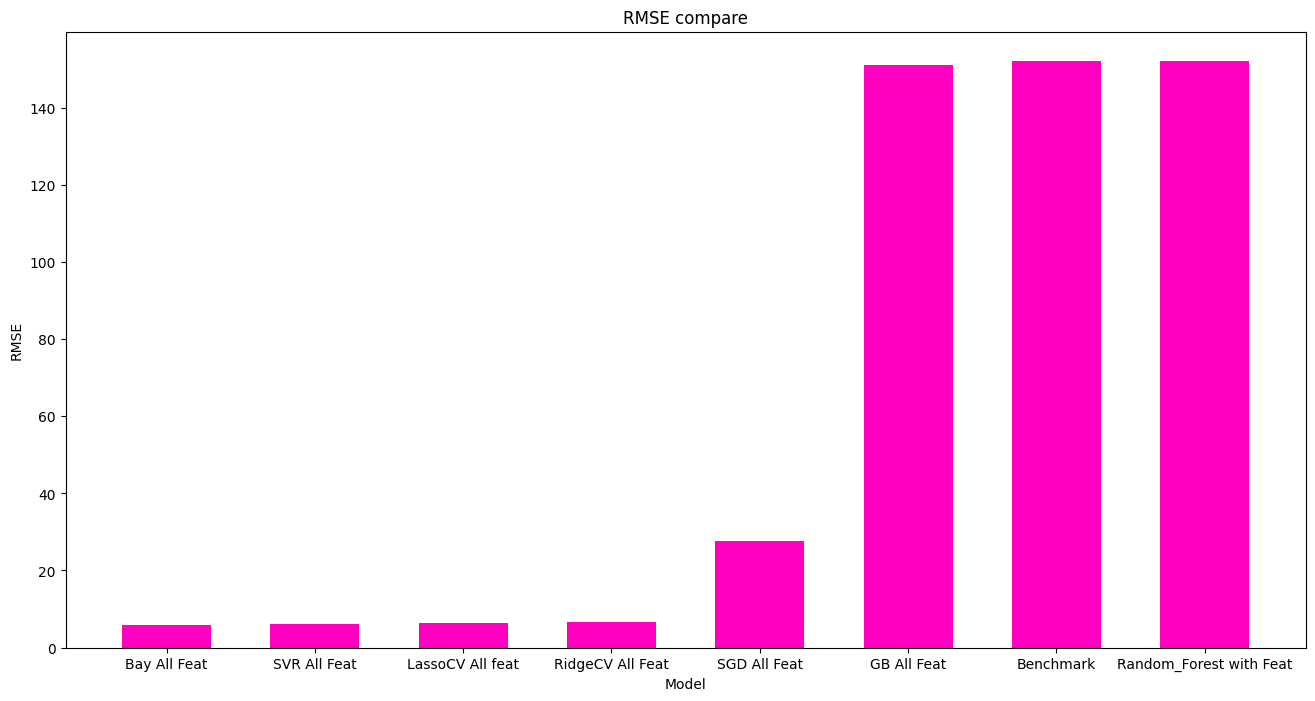

In [56]:

model_names = []
model_values = []
for name, value in RMSE_scores.items():
    model_names.append(name)
    model_values.append(value)

model_values = np.array(model_values)
model_names = np.array(model_names)

indices = np.argsort(model_values)
columns = model_names[indices[:8]]
values = model_values[indices][:8]

fig = plt.figure(figsize = (16,8))
plt.bar(np.arange(8), values ,width = 0.6, align="center", color = '#ff00c1')
plt.xticks(np.arange(8), columns)
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.title('RMSE compare')   
plt.show()

## Feature Selection

In this step we will select supporting features using sklearn's **SelectFromModel** library using Lasso regressor as it has lowest RMSE.

In [57]:
from sklearn.feature_selection import SelectFromModel

sfm = SelectFromModel(lasso_clf_feat)
sfm.fit(feature_minmax_transform, target_adj_close.values.ravel())
display(feature_minmax_transform.head())
sup = sfm.get_support()
zipped = zip(feature_minmax_transform,sup)
print(*zipped)

c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


,Open,High,Low,Volume,SP_open,SP_high,SP_low,SP_Ajclose,SP_volume,DJ_open,...,USO_Volume,SMA,Upper_band,Lower_band,DIF,MACD,RSI,STDEV,Open_Close,High_Low
Date,,,,,,,,,,,,,,,,,,,,,
2012-02-06,0.161629,0.163172,0.173293,0.079800,0.000802,0.000751,0.000876,0.000654,0.010742,0.017947,...,0.039726,0.169177,0.172713,0.159130,0.469324,0.496636,0.752948,0.048728,0.360666,0.020986
2012-02-07,0.162657,0.169069,0.174703,0.110188,0.000827,0.000817,0.000851,0.000692,0.013518,0.017561,...,0.068406,0.171044,0.173406,0.162209,0.470141,0.497562,0.795049,0.049773,0.298278,0.066618
2012-02-08,0.167258,0.168750,0.175617,0.099808,0.000917,0.000843,0.000939,0.000738,0.013900,0.018067,...,0.060095,0.172475,0.173409,0.165154,0.467453,0.497471,0.744992,0.049173,0.389780,0.054905
2012-02-09,0.169094,0.169754,0.176061,0.158591,0.000989,0.000891,0.000972,0.000757,0.014822,0.018507,...,0.029523,0.173624,0.173209,0.167741,0.463528,0.496267,0.725006,0.029228,0.426322,0.060761
2012-02-10,0.160479,0.163074,0.172562,0.096249,0.000826,0.000745,0.000877,0.000644,0.016748,0.018629,...,0.038906,0.174683,0.172159,0.171088,0.457848,0.493716,0.688044,0.032325,0.347891,0.026842


('Open', np.True_) ('High', np.True_) ('Low', np.True_) ('Volume', np.False_) ('SP_open', np.False_) ('SP_high', np.True_) ('SP_low', np.False_) ('SP_Ajclose', np.False_) ('SP_volume', np.False_) ('DJ_open', np.False_) ('DJ_high', np.False_) ('DJ_low', np.False_) ('DJ_Ajclose', np.False_) ('DJ_volume', np.False_) ('EG_open', np.False_) ('EG_high', np.False_) ('EG_low', np.False_) ('EG_Ajclose', np.False_) ('EG_volume', np.False_) ('EU_Price', np.False_) ('EU_open', np.False_) ('EU_high', np.False_) ('EU_low', np.False_) ('EU_Trend', np.True_) ('OF_Price', np.True_) ('OF_Open', np.False_) ('OF_High', np.False_) ('OF_Low', np.False_) ('OF_Volume', np.False_) ('OF_Trend', np.True_) ('OS_Price', np.False_) ('OS_Open', np.False_) ('OS_High', np.False_) ('OS_Low', np.False_) ('OS_Trend', np.False_) ('SF_Price', np.False_) ('SF_Open', np.False_) ('SF_High', np.False_) ('SF_Low', np.False_) ('SF_Volume', np.False_) ('SF_Trend', np.False_) ('USB_Price', np.False_) ('USB_Open', np.True_) ('USB_H

In [58]:
# Selecting Features which supports Model building process

feature_selected = feature_minmax_transform[['Open','High','Low','OF_Trend','USB_Trend','PLT_Trend','USDI_Price','GDX_Close','SMA','Upper_band','RSI','Open_Close']]
feature_selected_validation_X = validation_X[['Open','High','Low','OF_Trend','USB_Trend','PLT_Trend','USDI_Price','GDX_Close','SMA','Upper_band','RSI','Open_Close']]
display(feature_selected.head())
display(feature_selected_validation_X.head())

,Open,High,Low,OF_Trend,USB_Trend,PLT_Trend,USDI_Price,GDX_Close,SMA,Upper_band,RSI,Open_Close
Date,,,,,,,,,,,,
2012-02-06,0.161629,0.163172,0.173293,1.0,0.0,0.0,0.024742,0.422850,0.169177,0.172713,0.752948,0.360666
2012-02-07,0.162657,0.169069,0.174703,1.0,1.0,1.0,0.010472,0.419948,0.171044,0.173406,0.795049,0.298278
2012-02-08,0.167258,0.168750,0.175617,1.0,1.0,1.0,0.012120,0.416659,0.172475,0.173409,0.744992,0.389780
2012-02-09,0.169094,0.169754,0.176061,1.0,1.0,0.0,0.009830,0.413853,0.173624,0.173209,0.725006,0.426322
2012-02-10,0.160479,0.163074,0.172562,0.0,0.0,1.0,0.025859,0.406501,0.174683,0.172159,0.688044,0.347891


,Open,High,Low,OF_Trend,USB_Trend,PLT_Trend,USDI_Price,GDX_Close,SMA,Upper_band,RSI,Open_Close
Date,,,,,,,,,,,,
2026-04-07,0.800264,0.813388,0.842893,0.0,0.0,0.0,0.595923,0.798104,0.862774,0.877959,0.432206,0.251040
2026-04-08,0.829829,0.830540,0.864326,0.0,1.0,1.0,0.581681,0.829157,0.858348,0.859569,0.449661,0.529115
2026-04-09,0.821239,0.831690,0.876230,0.0,0.0,1.0,0.573024,0.830802,0.857126,0.854791,0.471660,0.324421
2026-04-10,0.826427,0.830320,0.876570,0.0,1.0,1.0,0.568277,0.840863,0.859044,0.859470,0.466417,0.410577
2026-04-13,0.817103,0.820215,0.865161,0.0,0.0,1.0,0.560458,0.834962,0.862976,0.863912,0.453990,0.349971


## Train Test Split

In [59]:
 for train_index, test_index in ts_split.split(feature_selected):
        X_train, X_test = feature_selected[:len(train_index)], feature_selected[len(train_index): (len(train_index)+len(test_index))]
        y_train, y_test = target_adj_close[:len(train_index)].values.ravel(), target_adj_close[len(train_index): (len(train_index)+len(test_index))].values.ravel()
     

## validation Feature Selected Benchmark & Solution Model

In [60]:
def feature_selected_validate_result(model, model_name):
    predicted = model.predict(feature_selected_validation_X)
    
    RSME_score = np.sqrt(mean_squared_error(validation_y, predicted))
    R2_score = r2_score(validation_y, predicted)
    
    print(model_name + '\n')
    print('RMSE: ', RSME_score)
    print('R2 score: ', R2_score)
    print('----------------------')


print('---------Benchmark-------------')  
dt = DecisionTreeRegressor(random_state=0)
benchmark_dt_fs = dt.fit(X_train,y_train)
feature_selected_validate_result(benchmark_dt_fs, 'Decision Tree')

feature_selected_solution_models = {}
 
print('--------Solution Models--------------')  
# Random Forest
random_forest_clf_fs = RandomForestRegressor(
    random_state=0, max_depth=3, max_features='sqrt', n_estimators=10
)
random_forest_parameters = {
    'n_estimators': [10, 50, 100],
    'max_features': ['sqrt', 'log2'],   # removed 'auto'
    'max_depth': [3, 5, 7],
}
grid_search_RF_fs = GridSearchCV(
    estimator=random_forest_clf_fs,
    param_grid=random_forest_parameters,
    cv=ts_split,
)
grid_search_RF_fs.fit(X_train, y_train)
feature_selected_validate_result(grid_search_RF_fs, 'Feature selected RandomForest GS')
feature_selected_solution_models['FS_RandomForest'] = grid_search_RF_fs

# Linear SVR
linear_svr_fs = SVR(C=50.0, epsilon=0, kernel='linear')
linear_svr_clf_fs = linear_svr_fs.fit(X_train, y_train)
feature_selected_validate_result(linear_svr_clf_fs, 'Feature selected LSVR')
feature_selected_solution_models['FS_LSVR'] = linear_svr_clf_fs

# Lasso
lasso_fs = LassoCV(alphas=1000, max_iter=3000, random_state=0)  # n_alphas → alphas
lasso_clf_fs = lasso_fs.fit(X_train, y_train)
feature_selected_validate_result(lasso_clf_fs, 'Feature selected LassoCV')
feature_selected_solution_models['FS_Lasso'] = lasso_clf_fs

# Ridge
ridge_fs = RidgeCV(gcv_mode='auto')
ridge_clf_fs = ridge_fs.fit(X_train, y_train)
feature_selected_validate_result(ridge_clf_fs, 'Feature selected RidgeCV')
feature_selected_solution_models['FS_RidgeCV'] = ridge_clf_fs

# Bayesian Ridge
bay = linear_model.BayesianRidge()
bay_feat_fs = bay.fit(X_train, y_train)
feature_selected_validate_result(bay_feat_fs, 'Feature selected BayRidge')
feature_selected_solution_models['Bay_Ridge'] = bay_feat_fs

# Gradient Boosting
regr = GradientBoostingRegressor(
    n_estimators=70, learning_rate=0.1,
    max_depth=4, random_state=0, loss='squared_error'  # 'ls' → 'squared_error'
)
GB_fs = regr.fit(X_train, y_train)
feature_selected_validate_result(GB_fs, 'Feature selected GB')
feature_selected_solution_models['GB_FS'] = GB_fs

# SGD
sgd = SGDRegressor(
    max_iter=1000, tol=1e-3,
    loss='squared_epsilon_insensitive',
    penalty='l1', alpha=0.1
)
sgd_fs = sgd.fit(X_train, y_train)
feature_selected_validate_result(sgd_fs, 'Feature selected SGD')
feature_selected_solution_models['sgd_fs'] = sgd_fs


---------Benchmark-------------
Decision Tree

RMSE:  157.45954082879334
R2 score:  -38.10379792464523
----------------------
--------Solution Models--------------
Feature selected RandomForest GS

RMSE:  153.30346025137814
R2 score:  -36.06678284284355
----------------------
Feature selected LSVR

RMSE:  6.115011761326976
R2 score:  0.9410239649032374
----------------------
Feature selected LassoCV

RMSE:  5.954644005849186
R2 score:  0.9440767266667631
----------------------
Feature selected RidgeCV

RMSE:  6.258608107605362
R2 score:  0.9382216228877762
----------------------
Feature selected BayRidge

RMSE:  5.94493548144181
R2 score:  0.9442589339865285
----------------------
Feature selected GB

RMSE:  153.3799499142313
R2 score:  -36.10378048172043
----------------------
Feature selected SGD

RMSE:  7.954209337747594
R2 score:  0.9002127597856283
----------------------


## Model Review

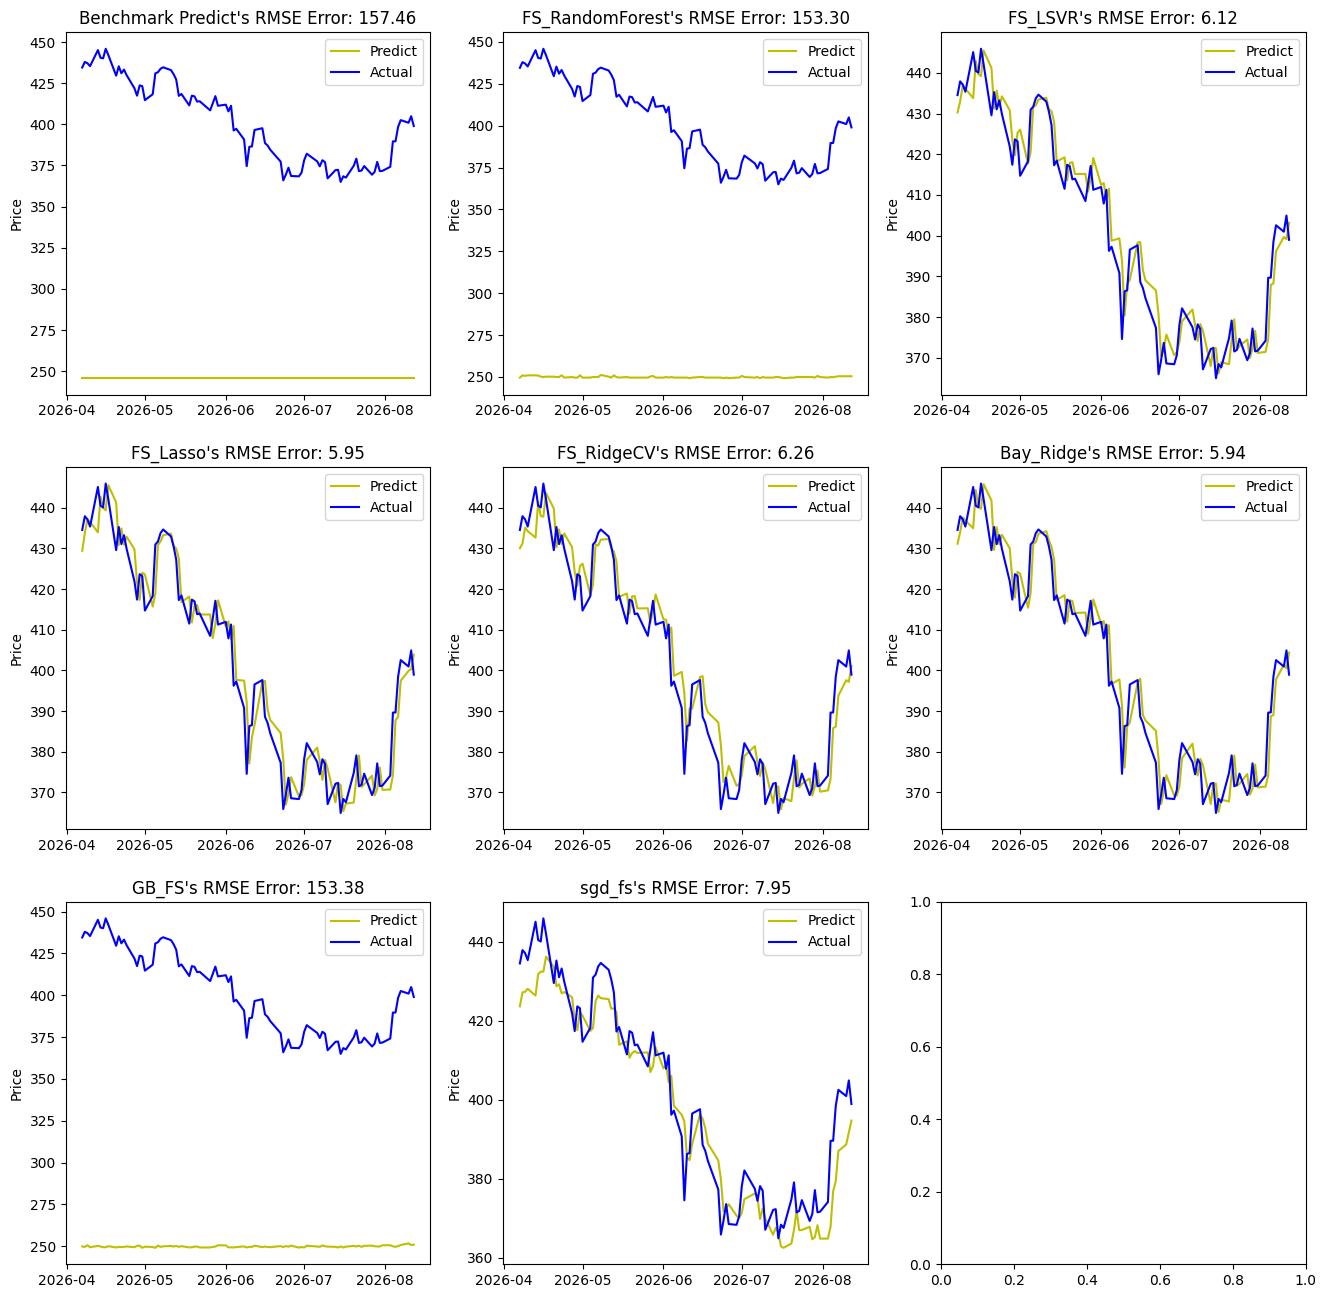

In [61]:
FS_RMSE_scores = {}

def fs_model_review(models):
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16, 16))

    #plot benchmark model
    benchmark_dt_predicted = benchmark_dt_fs.predict(feature_selected_validation_X)
    benchmark_RSME_score = np.sqrt(mean_squared_error(validation_y, benchmark_dt_predicted))
    FS_RMSE_scores['Benchmark'] = benchmark_RSME_score
    
    axes[0,0].plot(validation_y.index, benchmark_dt_predicted,'y', label='Predict')
    axes[0,0].plot(validation_y.index, validation_y,'b', label='Actual')
    axes[0,0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    axes[0,0].xaxis.set_major_locator(mdates.MonthLocator())
    axes[0,0].set_ylabel('Price')
    axes[0,0].set_title("Benchmark Predict's RMSE Error: " +"{0:.2f}".format(benchmark_RSME_score))
    axes[0,0].legend(loc='upper right')
    
    #plot block
    ax_x = 0
    ax_y = 1
    #plot solution model
    for name, model in models.items():
        predicted = model.predict(feature_selected_validation_X)
        RSME_score = np.sqrt(mean_squared_error(validation_y, predicted))

        R2_score = r2_score(validation_y, predicted)
    
        axes[ax_x][ax_y].plot(validation_y.index, predicted,'y', label='Predict')
        axes[ax_x][ax_y].plot(validation_y.index, validation_y,'b', label='Actual')
        axes[ax_x][ax_y].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        axes[ax_x][ax_y].xaxis.set_major_locator(mdates.MonthLocator())
        axes[ax_x][ax_y].set_ylabel('Price')
        axes[ax_x][ax_y].set_title(name + "'s RMSE Error: " +"{0:.2f}".format(RSME_score))
        axes[ax_x][ax_y].legend(loc='upper right')
        FS_RMSE_scores[name] = RSME_score
        if ax_x <=2:
            if ax_y < 2:
                ax_y += 1
            else:
                ax_x += 1
                ax_y = 0
    plt.show()

fs_model_review(feature_selected_solution_models)

### Comparison of RMSE of Feature selected models and Original Features model

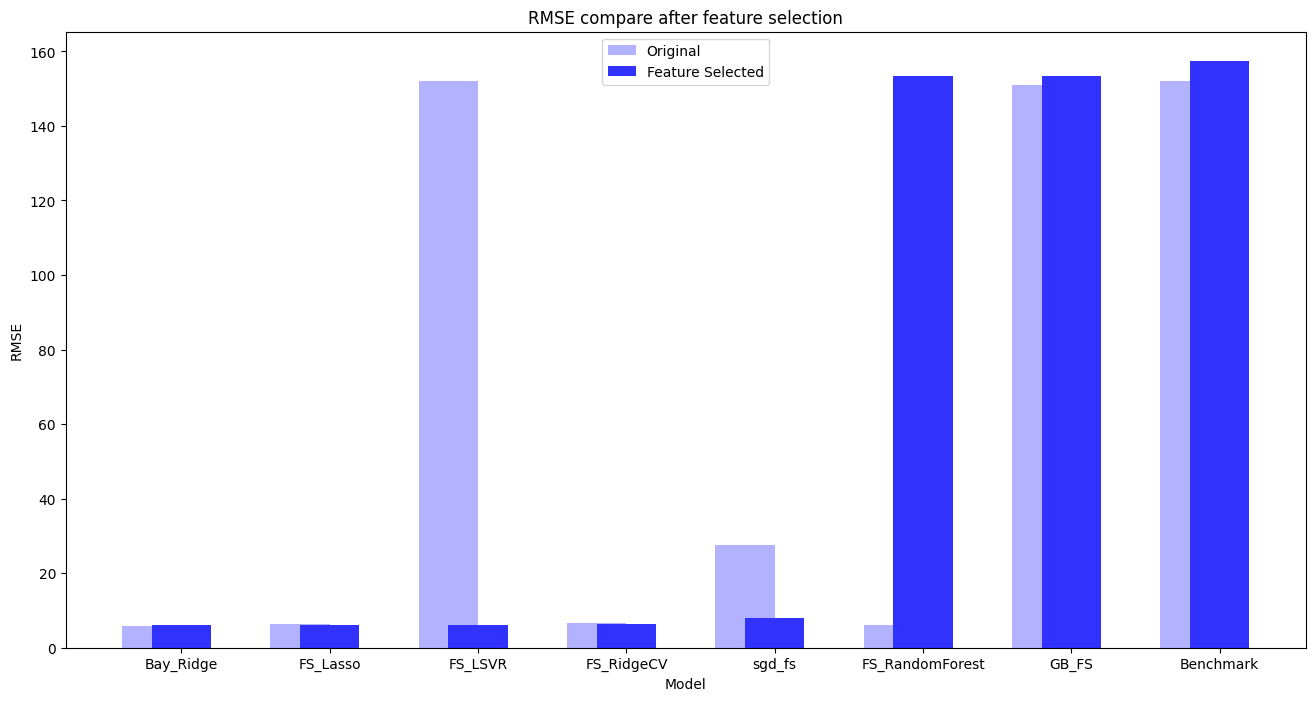

In [62]:

fs_model_names = []
fs_model_values = []
for name, value in FS_RMSE_scores.items():
    fs_model_names.append(name)
    fs_model_values.append(value)

fs_model_values = np.array(fs_model_values)
fs_model_names = np.array(fs_model_names)

fs_indices = np.argsort(fs_model_values)
fs_columns = fs_model_names[fs_indices[:8]]
fs_values = fs_model_values[fs_indices][:8]
origin_values = model_values[fs_indices][:8]

fig = plt.figure(figsize = (16,8))
plt.bar(np.arange(8) - 0.2 , origin_values ,width = 0.4, align="center", color = '#b2b2ff', label = "Original")
plt.bar(np.arange(8), fs_values ,width = 0.4, align="center", color = '#3232ff', label = "Feature Selected")
plt.xticks(np.arange(8), fs_columns)
plt.xlabel('Model')
plt.ylabel('RMSE')
plt.title('RMSE compare after feature selection')
plt.legend(loc = 'upper center')
plt.show()


**As we have seen from the above plot 3 Feature selected models performs better in RMSE error reduction and Feature selected Linear SVR is the best as it has RMSE of 0.716 in feature selected model and 0.741 with all features model. Also Lasso cv and Bayesian Ridge performs slightly better from original features model where as Ridge cv shows no improvement from features model.Where as four model performance degrades  after feature selection in which benchmark model has highest RMSE error and SGD model degrades most in comparison to others.**

# Ensemble Solution

So now we will ensemble top three performing models i.e, in case of all the features model Lasso,Bayesian ridge and Ridge are the best performing models so we will ensemble these three models while in case of feature selected models we will combine Lasso,Bayesian Ridge and Linear SVR and will compare all the feature ensemble models with feature selected ensemble models.

In [63]:
# Choosing the top three performing models to ensemble them
ensemble_solution_models = [lasso_clf_feat, bay_feat, ridge_clf_feat]
class EnsembleSolution:
    models = []
    def __init__(self, models):
        self.models = models
    def fit(self, X, y):
        for i in self.models:
            i.fit(X, y)
    def predict(self, X):
        result = 0
        for i in self.models:
            result = result + i.predict(X)
        
        result = result / len(self.models)
        
        return result

Ensemble Solution Model with Original features
RMSE:  6.114280535750647
R2 score:  0.9410380686232405


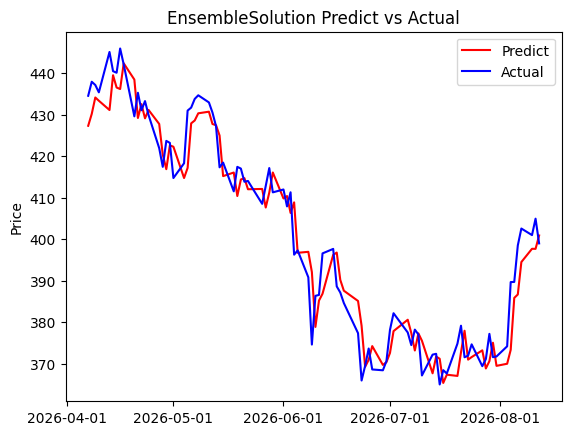

In [64]:
print("Ensemble Solution Model with Original features")
EnsembleModel = EnsembleSolution(ensemble_solution_models)
validate_result(EnsembleModel,'EnsembleSolution')

Ensemble solution with all features shows best result (with RMSE 0.699 and R2 score of 0.887) in comparison with other solution models.

In [65]:
ensemble_solution_model_fs = [lasso_clf_fs,bay_feat_fs,linear_svr_clf_fs]

print("Ensemble Solution Model with Selected features")
EnsembleModel_fs = EnsembleSolution(ensemble_solution_model_fs)
feature_selected_validate_result(EnsembleModel_fs,'EnsembleSolution with FS')


Ensemble Solution Model with Selected features
EnsembleSolution with FS

RMSE:  5.966658509483446
R2 score:  0.9438508296370169
----------------------


Ensemble solution with feature selection has better solution (RMSE 0.711 and  R2score 0.884 ) but Lasso has best performance (RMSE - 0.709 and R2 score 0.884)

## Train Model Multiple Times
By the train_reg_multipletimes function.This function would train the model several times (I choosed 7 times ), and use different parameters on TimeSeriesSplit in each time, average the R2 and RMSE.
I will apply this function on Benchmark model and on top performing solution models with all features which are Linear SVR, Lasso, Ridge and Bayesian ridge and compare the same.

In [66]:
def train_reg_multipletimes(model, times):
    total_rmse = 0
    total_r2 = 0
    for i in range(times):
        reg = model
        for train_index, test_index in TimeSeriesSplit(n_splits=i+2).split(feature_minmax_transform):
            X_train, X_test = feature_minmax_transform[:len(train_index)], feature_minmax_transform[len(train_index): (len(train_index)+len(test_index))]
            y_train, y_test = target_adj_close[:len(train_index)].values.ravel(), target_adj_close[len(train_index): (len(train_index)+len(test_index))].values.ravel()
            reg.fit(X_train, y_train)
        predicted = reg.predict(validation_X)
        rmse, r2 = print_result(validation_y, predicted, [0,len(validation_y)])
        total_rmse += rmse
        total_r2 += r2
    return total_rmse / times, total_r2 / times

def print_result(actual, predict, index):
    RMSE_score = np.sqrt(mean_squared_error(actual, predict))
    print('From {} to {}'.format(index[0],index[-1]))
    print('RMSE: ', RMSE_score)
    R2_score = r2_score(actual, predict)
    print('R2 score: ', R2_score)
    print('---------------------')
    return RMSE_score, R2_score

In [67]:
print('Benchmark')
t_multiple_benchmark_RMSE,t_multiple_benchmark_R2 = train_reg_multipletimes(benchmark_dt, 7)
print('RMSE: {} //  R2: {}\n'.format(t_multiple_benchmark_RMSE, t_multiple_benchmark_R2))


Benchmark
From 0 to 89
RMSE:  223.25978511355524
R2 score:  -77.61437814845723
---------------------
From 0 to 89
RMSE:  214.43667732433713
R2 score:  -71.5235604628967
---------------------
From 0 to 89
RMSE:  217.54532339716226
R2 score:  -73.64152122278112
---------------------
From 0 to 89
RMSE:  210.67974460579808
R2 score:  -69.00459462345165
---------------------
From 0 to 89
RMSE:  194.03514180092702
R2 score:  -58.38021467149499
---------------------
From 0 to 89
RMSE:  178.6862269786269
R2 score:  -49.35738109527609
---------------------
From 0 to 89
RMSE:  171.79497739217558
R2 score:  -45.548094130098384
---------------------
RMSE: 201.4911252303689 //  R2: -63.5813920506366



In [68]:
print('LSVR')
t_multiple_LSVR_RMSE,t_multiple_LSVR_R2 = train_reg_multipletimes(linear_svr_clf_feat, 7)
print(' RMSE: {} //  R2: {}'.format(t_multiple_LSVR_RMSE, t_multiple_LSVR_R2))

LSVR
From 0 to 89
RMSE:  152.7381187791243
R2 score:  -35.79390249610269
---------------------
From 0 to 89
RMSE:  120.03071574528015
R2 score:  -21.723005325706076
---------------------
From 0 to 89
RMSE:  74.83054643877827
R2 score:  -7.831588226614922
---------------------
From 0 to 89
RMSE:  58.258573973693764
R2 score:  -4.3530423413216655
---------------------
From 0 to 89
RMSE:  56.1302044931497
R2 score:  -3.9690598485168715
---------------------
From 0 to 89
RMSE:  50.70554183566918
R2 score:  -3.055009112187771
---------------------
From 0 to 89
RMSE:  46.40579107959744
R2 score:  -2.3964508915800136
---------------------
 RMSE: 79.87135604932755 //  R2: -11.303151177432861


In [69]:
print('Lasso')
t_multiple_lasso_RMSE,t_multiple_lasso_R2 = train_reg_multipletimes(lasso_clf_feat, 7)
print(' RMSE: {} //  R2: {}'.format(t_multiple_lasso_RMSE, t_multiple_lasso_R2))

Lasso


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


From 0 to 89
RMSE:  25.347661238722
R2 score:  -0.013343689426355887
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  13.57476161843099
R2 score:  0.7093666804734079
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  7.927090227728089
R2 score:  0.9008920298092125
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  7.504549264216658
R2 score:  0.9111760250233361
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  6.997473464359182
R2 score:  0.9227740073993012
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  6.71237471047138
R2 score:  0.9289386647617556
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  6.386622367216226
R2 score:  0.9356685331691892
---------------------
 RMSE: 10.635790413020645 //  R2: 0.756496035887121


In [70]:
print('Ridge')
t_multiple_ridge_RMSE,t_multiple_ridge_R2 = train_reg_multipletimes(ridge_clf_feat, 7)
print(' RMSE: {} //  R2: {}'.format(t_multiple_ridge_RMSE, t_multiple_ridge_R2))

Ridge
From 0 to 89
RMSE:  43.26667071342598
R2 score:  -1.9524866009801496
---------------------
From 0 to 89
RMSE:  25.604012338532762
R2 score:  -0.03394404028622455
---------------------
From 0 to 89
RMSE:  9.86267994571425
R2 score:  0.8465839281193744
---------------------
From 0 to 89
RMSE:  9.412490502402298
R2 score:  0.8602698643670588
---------------------
From 0 to 89
RMSE:  8.54516206498871
R2 score:  0.8848347150994706
---------------------
From 0 to 89
RMSE:  7.580503030086279
R2 score:  0.909368946143162
---------------------
From 0 to 89
RMSE:  6.907596436860728
R2 score:  0.9247450810649459
---------------------
 RMSE: 15.882730718858713 //  R2: 0.3484816990753768


In [71]:
print('BayRidge')
t_multiple_bayridge_RMSE,t_multiple_bayridge_R2 = train_reg_multipletimes(bay_feat, 7)
print(' RMSE: {} //  R2: {}'.format(t_multiple_bayridge_RMSE, t_multiple_bayridge_R2))

BayRidge
From 0 to 89
RMSE:  14.47021305856433
R2 score:  0.669759122176644
---------------------
From 0 to 89
RMSE:  10.160704897703578
R2 score:  0.8371721625792024
---------------------
From 0 to 89
RMSE:  6.038334072411495
R2 score:  0.9424937229601981
---------------------
From 0 to 89
RMSE:  6.110015390210312
R2 score:  0.9411203002134245
---------------------
From 0 to 89
RMSE:  6.005965238012631
R2 score:  0.9431086018442619
---------------------
From 0 to 89
RMSE:  5.966117545798273
R2 score:  0.9438610106403775
---------------------
From 0 to 89
RMSE:  5.9198843620792925
R2 score:  0.9447277141899518
---------------------
 RMSE: 7.810176366397131 //  R2: 0.8888918049434372


In [72]:
print('Ensemble')
t_multiple_ensemble_RMSE,t_multiple_ensemble_R2 = train_reg_multipletimes(EnsembleSolution(ensemble_solution_models), 7)
print(' RMSE: {} //  R2: {}\n'.format(t_multiple_ensemble_RMSE, t_multiple_ensemble_R2))

Ensemble


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


From 0 to 89
RMSE:  27.539657350934903
R2 score:  -0.19618415009585521
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  16.231580625486004
R2 score:  0.5844697882609162
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  7.593731505693586
R2 score:  0.9090523558669266
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  7.3999145170618075
R2 score:  0.9136356747458441
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  6.924851405797669
R2 score:  0.9243686424197248
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  6.555690185334502
R2 score:  0.9322174628365185
---------------------


c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(
c:\Users\Isfar\AppData\Local\Programs\Python\Python310\lib\site-pack

From 0 to 89
RMSE:  6.229392131805259
R2 score:  0.9387970552370813
---------------------
 RMSE: 11.210688246016247 //  R2: 0.7151938327530224



In [73]:
def cross_validate(model, ts_split):
    clf = model
    total_rmse = 0
    total_r2 = 0
    count = 0
    for train_index, test_index in ts_split.split(validation_X):
        X_test1, X_test2 = validation_X[:len(train_index)], validation_X[len(train_index): (len(train_index)+len(test_index))]
        y_test1, y_test2 = validation_y[:len(train_index)].values.ravel(), validation_y[len(train_index): (len(train_index)+len(test_index))].values.ravel()
        predicted_test1 = clf.predict(X_test1)
        temp1_RMSE, temp1_R2 = print_result(y_test1, predicted_test1, train_index)

        predicted_test2 = clf.predict(X_test2)
        temp2_RMSE, temp2_R2 = print_result(y_test2, predicted_test2, test_index)
        
        total_rmse += temp1_RMSE + temp2_RMSE
        total_r2 += temp1_R2 + temp2_R2
        count += 2
    return total_rmse / count, total_r2 / count



# Cross Validation

In [74]:
timeseries_cv = TimeSeriesSplit(n_splits=10)
test_bench__RMSE, test_bench_R2 = cross_validate(benchmark_dt,timeseries_cv)

From 0 to 8
RMSE:  208.5867157579783
R2 score:  -3022.9729355528993
---------------------
From 9 to 16
RMSE:  196.54245104194152
R2 score:  -1173.508252574702
---------------------
From 0 to 16
RMSE:  203.0078587886061
R2 score:  -691.2821984443453
---------------------
From 17 to 24
RMSE:  196.36145697807513
R2 score:  -739.071668476029
---------------------
From 0 to 24
RMSE:  200.90493440443998
R2 score:  -603.9116150181776
---------------------
From 25 to 32
RMSE:  187.949770964081
R2 score:  -965.4115141228835
---------------------
From 0 to 32
RMSE:  197.84220433596187
R2 score:  -434.3523195454796
---------------------
From 33 to 40
RMSE:  180.57239167384648
R2 score:  -4270.6452628076
---------------------
From 0 to 40
RMSE:  194.59287437280096
R2 score:  -315.65712838191195
---------------------
From 41 to 48
RMSE:  159.87734113388282
R2 score:  -450.96028589751023
---------------------
From 0 to 48
RMSE:  189.36025328521166
R2 score:  -129.35234925534087
---------------------

In [75]:
test_lsvr__RMSE, test_lsvr_R2 = cross_validate(lsvr_grid_search_feat,timeseries_cv)

From 0 to 8
RMSE:  5.505222178231808
R2 score:  -1.1064652998710685
---------------------
From 9 to 16
RMSE:  6.144982910660894
R2 score:  -0.14811316279456777
---------------------
From 0 to 16
RMSE:  5.815060370248426
R2 score:  0.43197700328293887
---------------------
From 17 to 24
RMSE:  5.846718113736593
R2 score:  0.34387649119765107
---------------------
From 0 to 24
RMSE:  5.825209566962338
R2 score:  0.49144980558557405
---------------------
From 25 to 32
RMSE:  4.691157594625207
R2 score:  0.39794171142894197
---------------------
From 0 to 32
RMSE:  5.571524841866348
R2 score:  0.6547361406638004
---------------------
From 33 to 40
RMSE:  3.875368680476284
R2 score:  -0.9675171622993648
---------------------
From 0 to 40
RMSE:  5.283499852563429
R2 score:  0.7665581039495268
---------------------
From 41 to 48
RMSE:  9.732718652104904
R2 score:  -0.674922740498465
---------------------
From 0 to 48
RMSE:  6.230826422177231
R2 score:  0.8588657184829629
---------------------

In [76]:
test_ridge__RMSE, test_ridge_R2 = cross_validate(ridge_clf_feat,timeseries_cv)

From 0 to 8
RMSE:  10.133183019808426
R2 score:  -6.13668258277325
---------------------
From 9 to 16
RMSE:  4.956639925239771
R2 score:  0.2530043398722751
---------------------
From 0 to 16
RMSE:  8.119253869676086
R2 score:  -0.10736222633386583
---------------------
From 17 to 24
RMSE:  7.951204876301854
R2 score:  -0.21346477785514129
---------------------
From 0 to 24
RMSE:  8.065859135104365
R2 score:  0.02498346096951609
---------------------
From 25 to 32
RMSE:  4.412356422425759
R2 score:  0.46737730535175026
---------------------
From 0 to 32
RMSE:  7.34888819311494
R2 score:  0.39931573144298793
---------------------
From 33 to 40
RMSE:  4.092693283226514
R2 score:  -1.194375150436458
---------------------
From 0 to 40
RMSE:  6.836423807946875
R2 score:  0.6091650810740592
---------------------
From 41 to 48
RMSE:  8.408624671237568
R2 score:  -0.2501910224999224
---------------------
From 0 to 48
RMSE:  7.116872823704412
R2 score:  0.8158720909703359
---------------------


In [77]:
test_lasso__RMSE, test_lasso_R2 = cross_validate(lasso_clf_feat,timeseries_cv)

From 0 to 8
RMSE:  7.261223031737309
R2 score:  -2.664579609381886
---------------------
From 9 to 16
RMSE:  5.559937889512991
R2 score:  0.06009660718158849
---------------------
From 0 to 16
RMSE:  6.516185793092138
R2 score:  0.28674572981454216
---------------------
From 17 to 24
RMSE:  6.379638664670602
R2 score:  0.21881580130402845
---------------------
From 0 to 24
RMSE:  6.472804121447549
R2 score:  0.3720925356051631
---------------------
From 25 to 32
RMSE:  5.003788315067382
R2 score:  0.31502242886784615
---------------------
From 0 to 32
RMSE:  6.148991072406743
R2 score:  0.5794567145770426
---------------------
From 33 to 40
RMSE:  5.149653449597695
R2 score:  -2.474149368658475
---------------------
From 0 to 40
RMSE:  5.967154927518572
R2 score:  0.7022374807628737
---------------------
From 41 to 48
RMSE:  9.552912151918452
R2 score:  -0.6136078895271182
---------------------
From 0 to 48
RMSE:  6.68527089455793
R2 score:  0.8375277364672893
---------------------
Fro

In [78]:
test_bay_RMSE, test_bay_R2 = cross_validate(bay_feat,timeseries_cv)

From 0 to 8
RMSE:  5.597026641213937
R2 score:  -1.1773054313524787
---------------------
From 9 to 16
RMSE:  5.663730312739584
R2 score:  0.02467699447718419
---------------------
From 0 to 16
RMSE:  5.628515076589336
R2 score:  0.4678364427840538
---------------------
From 17 to 24
RMSE:  6.124042945861539
R2 score:  0.2801570720672404
---------------------
From 0 to 24
RMSE:  5.791698574572888
R2 score:  0.49728410295385794
---------------------
From 25 to 32
RMSE:  4.3748806338389405
R2 score:  0.4763864096951661
---------------------
From 0 to 32
RMSE:  5.481956501962384
R2 score:  0.6657478968166559
---------------------
From 33 to 40
RMSE:  3.885013428688328
R2 score:  -0.9773225885868171
---------------------
From 0 to 40
RMSE:  5.208945374929933
R2 score:  0.773099731972085
---------------------
From 41 to 48
RMSE:  9.22410117001537
R2 score:  -0.5044389053876319
---------------------
From 0 to 48
RMSE:  6.04933784171423
R2 score:  0.8669677642258682
---------------------
From

In [79]:
test_ensemble_RMSE, test_ensemble_R2 = cross_validate(EnsembleSolution(ensemble_solution_models),timeseries_cv)

From 0 to 8
RMSE:  7.48160778153723
R2 score:  -2.8904020143573907
---------------------
From 9 to 16
RMSE:  5.2555165264691155
R2 score:  0.16020332778632795
---------------------
From 0 to 16
RMSE:  6.529272217126346
R2 score:  0.2838780029628535
---------------------
From 17 to 24
RMSE:  6.708662201101802
R2 score:  0.13616034594626303
---------------------
From 0 to 24
RMSE:  6.587208558649657
R2 score:  0.34970031396982204
---------------------
From 25 to 32
RMSE:  4.404001832700414
R2 score:  0.46939238794306815
---------------------
From 0 to 32
RMSE:  6.1297703056924435
R2 score:  0.5820817081557088
---------------------
From 33 to 40
RMSE:  4.256306892112922
R2 score:  -1.3733311955633565
---------------------
From 0 to 40
RMSE:  5.811833930149036
R2 score:  0.7175368520505367
---------------------
From 41 to 48
RMSE:  8.92085543916409
R2 score:  -0.4071469190602852
---------------------
From 0 to 48
RMSE:  6.423056766452679
R2 score:  0.8500229760410081
---------------------


In [80]:
print('Benchmark RMSE: {} // Benchmark R2: {}'.format(test_bench__RMSE, test_bench_R2))
print('LSVR RMSE: {} // LSVR R2: {}'.format(test_lsvr__RMSE, test_lsvr_R2))
print('Lasso RMSE: {} // Lasso R2: {}'.format(test_lasso__RMSE, test_lasso_R2))
print('bayesian ridge RMSE: {} // Bayesian ridge R2: {}'.format(test_bay_RMSE, test_bay_R2))

print('Ensemble RMSE: {} // Ensemble R2: {}'.format(test_ensemble_RMSE, test_ensemble_R2))

Benchmark RMSE: 178.16246626183255 // Benchmark R2: -988.3729703787192
LSVR RMSE: 5.9372221174237305 // LSVR R2: 0.11481048680657654
Lasso RMSE: 6.246610096252587 // Lasso R2: -0.08161414412469177
bayesian ridge RMSE: 5.727374450699239 // Bayesian ridge R2: 0.145300446827551
Ensemble RMSE: 6.076021460626565 // Ensemble R2: 0.02654731319849978


In [108]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# --- Step 1: Load the full dataset ---
df_pred = pd.read_csv(
    r'C:\Users\Isfar\OneDrive\Desktop\safi MJ\kaggle\input\FINAL_USO_2026.csv',
    na_values=['null'], index_col='Date', parse_dates=True
)

# --- Step 2: Recompute technical indicators (same as training) ---
gld_close = df_pred['Adj Close']

SMA_pred   = gld_close.rolling(window=15, min_periods=15, center=False).mean()
STD_pred   = gld_close.rolling(window=15, min_periods=15, center=False).std()
Upper_pred = SMA_pred + (2 * STD_pred)
Lower_pred = SMA_pred - (2 * STD_pred)

delta      = gld_close.diff()
up_pred    = delta.clip(lower=0)
down_pred  = delta.clip(upper=0).abs()
rUp        = up_pred.ewm(com=14, adjust=False).mean()
rDown      = down_pred.ewm(com=14, adjust=False).mean()
RSI_pred   = 100 - 100 / (1 + rUp / rDown)

emafast_p  = gld_close.ewm(span=12, min_periods=12, adjust=True, ignore_na=False).mean()
emaslow_p  = gld_close.ewm(span=26, min_periods=26, adjust=True, ignore_na=False).mean()
DIF_pred   = emafast_p - emaslow_p
MACD_pred  = DIF_pred.ewm(span=9, min_periods=9, adjust=True, ignore_na=False).mean()
STDEV_pred = gld_close.rolling(5).std()

df_pred['SMA']        = SMA_pred
df_pred['Upper_band'] = Upper_pred
df_pred['Lower_band'] = Lower_pred
df_pred['RSI']        = RSI_pred
df_pred['DIF']        = DIF_pred
df_pred['MACD']       = MACD_pred
df_pred['STDEV']      = STDEV_pred
df_pred['Open_Close'] = df_pred['Open'] - df_pred['Close']
df_pred['High_Low']   = df_pred['High'] - df_pred['Low']

# Drop first 33 rows (same as training warm-up period)
df_pred = df_pred[33:]

# --- Step 3: Use the latest available date ---
date = -1
latest_date = df_pred.index[date]
latest_row  = df_pred.iloc[[date]]  # keep as DataFrame (single row)

# --- Step 4: Apply a scaler fitted on the same data as training ---
# (scaler was fit on test[feature_columns]; we replicate that here)
scaler_pred = MinMaxScaler()
scaler_pred.fit(df_pred[feature_columns])

latest_scaled    = scaler_pred.transform(latest_row[feature_columns])
latest_scaled_df = pd.DataFrame(latest_scaled, columns=feature_columns, index=latest_row.index)

# --- Step 5: Predict with the Ensemble model ---
predicted_price = EnsembleModel.predict(latest_scaled_df)[0]

# --- Step 6: Print result ---
print('=' * 50)
print('Latest date in dataset :', latest_date.date())
print('Predicted Gold (GLD) Adj Close for next trading day: ${:.4f}'.format(predicted_price))
print('=' * 50)


Latest date in dataset : 2026-08-13
Predicted Gold (GLD) Adj Close for next trading day: $395.7041
